# Analyzing the ablation test results
Effects of the mean-vector intervention of notebook 3 (bin means, the residue's own angle): the change of log p of the original amino acid at the masked residue, against the unedited pass.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import display
import torch
from transformers import AutoTokenizer, EsmForMaskedLM

from biomanifolds import config, theme
from biomanifolds.datasets import swissprot

theme.use()  # Nunito fonts and the project defaults

MODEL = "facebook/esm2_t30_150M_UR50D"
AA = "ACDEFGHIKLMNPQRSTVWY"
RESULTS = config.data_path("steering") / "nb03_1M"
WINDOW = 10

device = "cuda" if torch.cuda.is_available() else "cpu"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
model = EsmForMaskedLM.from_pretrained(MODEL, attn_implementation="sdpa").eval().to(device)

results = pl.read_parquet(RESULTS / "results" / "*.parquet").rechunk()  # one chunk per column, so that to_numpy() gives views, not copies
LAYERS = json.loads((RESULTS / "metadata.json").read_text())["layers"]

# effect of the mean-vector intervention, per residue and layer
unedited = results.filter(pl.col("edit") == "none").select("accession", "i", "layer", ll_unedited="log_likelihood", top1_unedited="top1_aa")
effects = (
    results.filter(pl.col("edit") == "bin_means")
    .join(unedited, on=["accession", "i", "layer"])
    .with_columns(delta_ll=pl.col("log_likelihood") - pl.col("ll_unedited"))
    .select("accession", "i", "aa", "helix_face", "layer", "delta_ll", "ll_unedited", "log_likelihood", "top1_unedited", "top1_aa")
)
effects.sort("delta_ll")[:10]

(null): No such file or directory


(null): No such file or directory


Loading weights:   0%|          | 0/491 [00:00<?, ?it/s]

accession,i,aa,helix_face,layer,delta_ll,ll_unedited,log_likelihood,top1_unedited,top1_aa
str,i32,str,f32,i32,f32,f32,f32,str,str
"""Q38XI1""",227,"""D""",-173.270432,30,-2.573795,-9.110226,-11.684021,"""V""","""V"""
"""Q9H694""",891,"""D""",175.154419,30,-2.515702,-4.360938,-6.87664,"""I""","""I"""
"""Q8L783""",113,"""R""",151.392395,28,-2.477475,-3.081444,-5.558919,"""L""","""L"""
"""Q631G4""",521,"""R""",162.367722,28,-2.398017,-2.920574,-5.318591,"""F""","""F"""
"""Q815G7""",521,"""R""",163.531876,28,-2.362079,-3.002261,-5.36434,"""F""","""F"""
"""Q9JMK2""",206,"""N""",179.397598,30,-2.337754,-5.661827,-7.999581,"""L""","""L"""
"""Q03Q51""",226,"""D""",-169.482834,30,-2.320405,-8.996839,-11.317244,"""V""","""V"""
"""Q791V5""",89,"""K""",174.425247,30,-2.286478,-5.187308,-7.473785,"""L""","""L"""
"""P95690""",727,"""E""",-178.342514,30,-2.222807,-6.408572,-8.631379,"""V""","""V"""


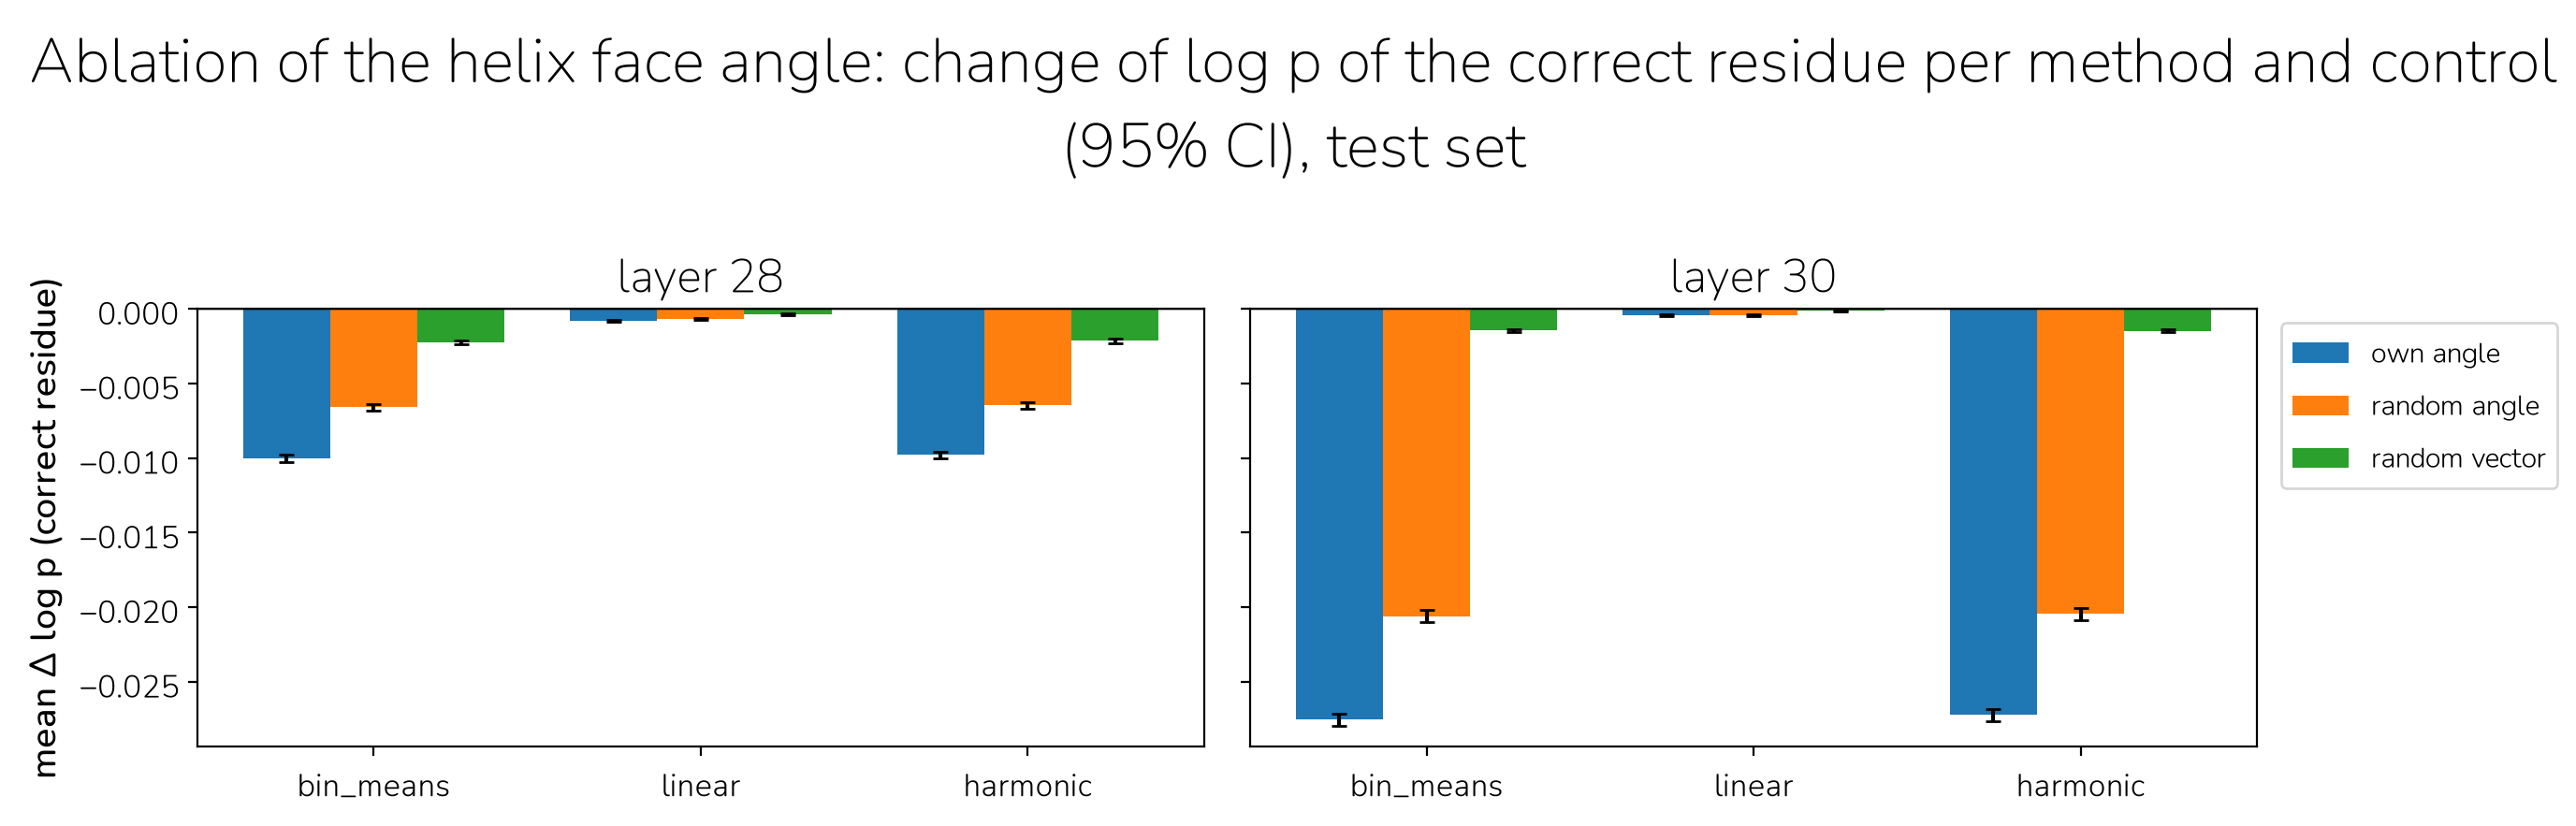

In [2]:
# Mean effect of each ablation method and control on log p of the correct residue, per layer, over all 1M residues;
# 95% confidence intervals from the protein bootstrap of notebook 3 (summary.parquet)
summary = pl.read_parquet(RESULTS / "summary.parquet")
METHODS, CONTROLS = ["bin_means", "linear", "harmonic"], ["", " | random angle", " | random vector"]
fig, axes = plt.subplots(1, len(LAYERS), figsize=(7 * len(LAYERS), 4.5), sharey=True)
width = 0.8 / len(CONTROLS)
for ax, layer in zip(axes, LAYERS):
    for k, control in enumerate(CONTROLS):
        rows = [summary.filter((pl.col("layer") == layer) & (pl.col("edit") == method + control)).row(0, named=True) for method in METHODS]
        values = np.array([r["mean_delta_ll"] for r in rows])
        errors = np.array([[r["mean_delta_ll"] - r["ll_ci_low"], r["ll_ci_high"] - r["mean_delta_ll"]] for r in rows]).T
        ax.bar(np.arange(len(METHODS)) + (k - (len(CONTROLS) - 1) / 2) * width, values, width, yerr=errors, capsize=3,
               label=control.removeprefix(" | ") or "own angle")
    ax.set_xticks(np.arange(len(METHODS)), METHODS)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.set_title(f"layer {layer}")
axes[0].set_ylabel("mean Δ log p (correct residue)")
axes[-1].legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.01, 1))  # outside, to the right
fig.suptitle("Ablation of the helix face angle: change of log p of the correct residue per method and control (95% CI), test set")
plt.tight_layout()
plt.show()

## Distribution of the effects

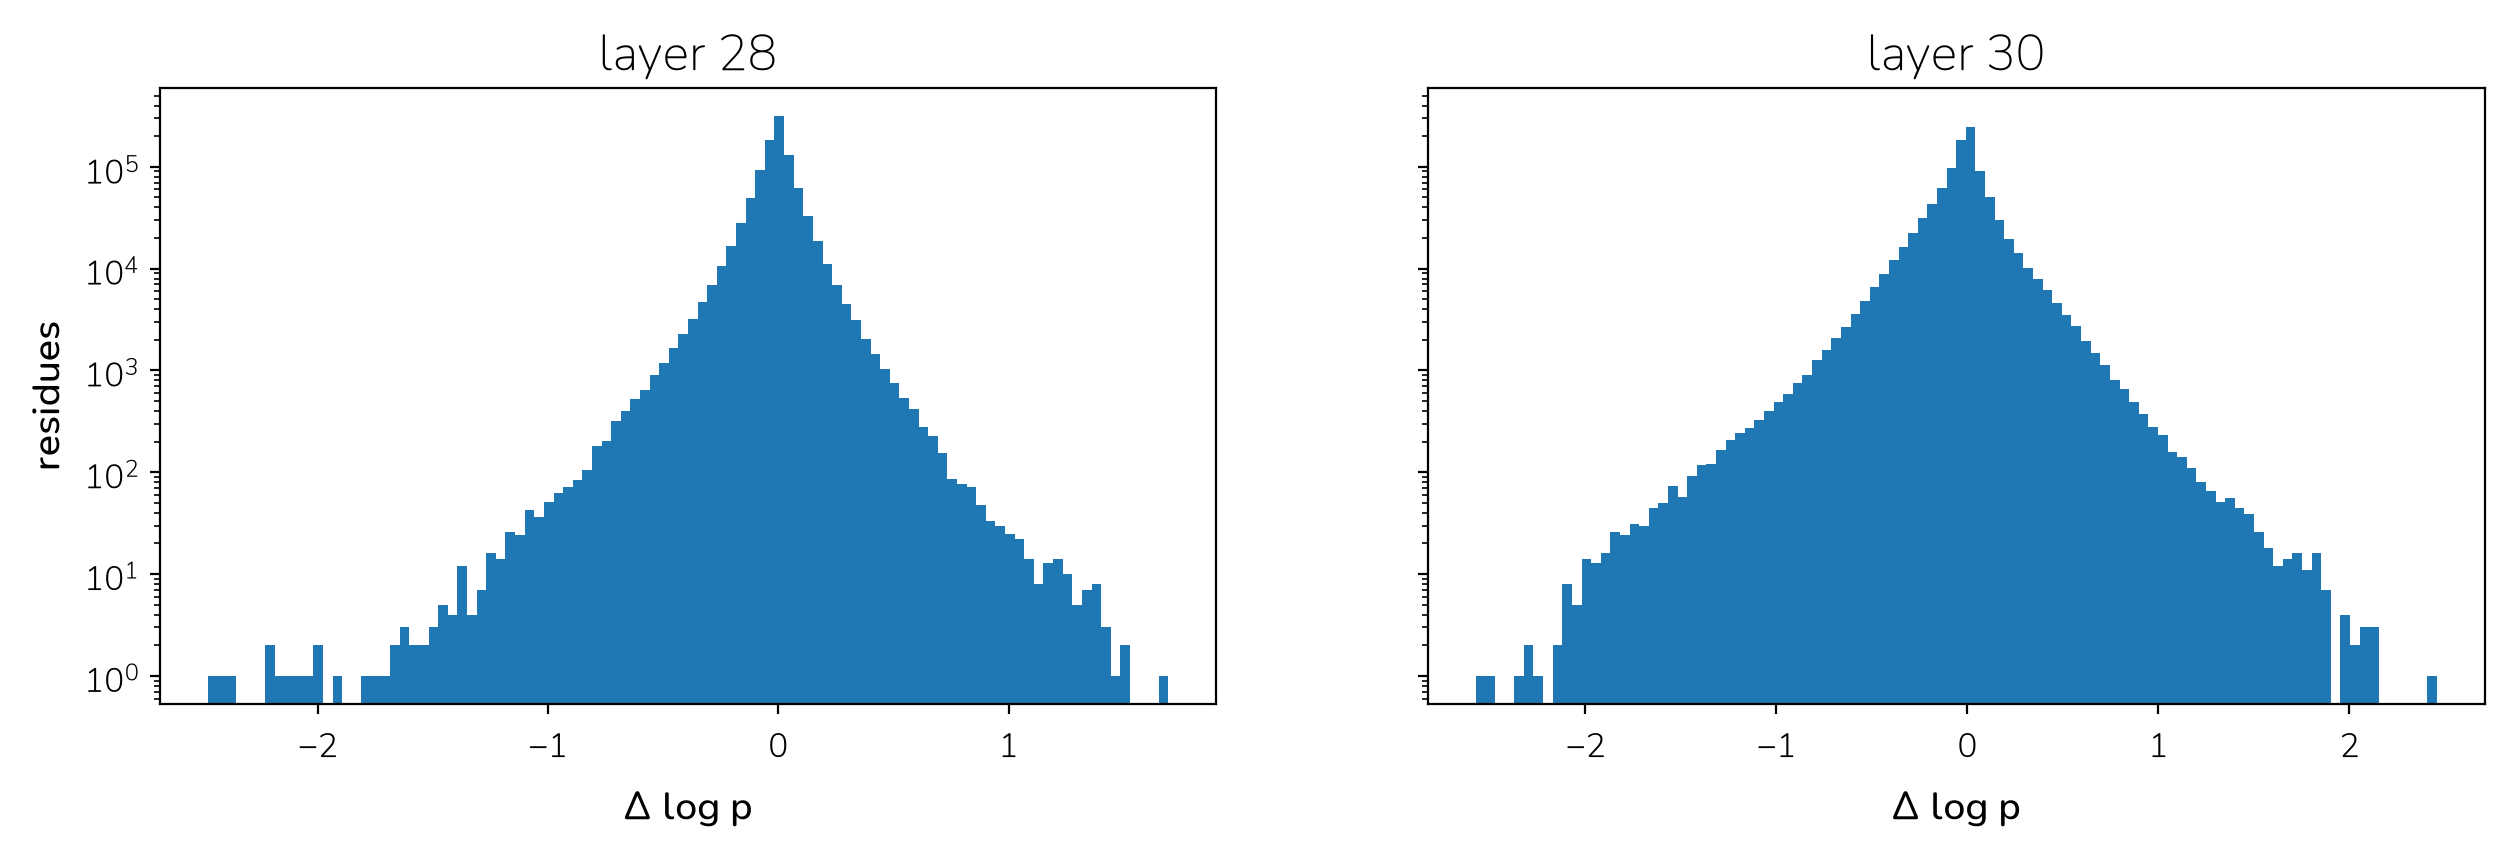

In [3]:
fig, axes = plt.subplots(1, len(LAYERS), figsize=(15, 4), sharey=True)
for ax, layer in zip(axes, LAYERS):
    ax.hist(effects.filter(pl.col("layer") == layer)["delta_ll"], bins=100)
    ax.set_yscale("log")
    ax.set_title(f"layer {layer}")
    ax.set_xlabel("Δ log p")
axes[0].set_ylabel("residues")
plt.show()

In [4]:
# Mean-vector edits that turned a correct top-1 prediction into a wrong one: the 10 largest drops of log p per layer
sequences = pl.read_parquet(swissprot.swissprot_dir() / "swissprot.parquet", columns=["accession", "sequence"])


def context(sequence, i):
    """The sequence around position i, with the masked residue in brackets."""
    return f"{sequence[max(0, i - WINDOW):i]}[{sequence[i]}]{sequence[i + 1:i + 1 + WINDOW]}"


correct_to_wrong = effects.filter((pl.col("top1_unedited") == pl.col("aa")) & (pl.col("top1_aa") != pl.col("aa")))
wrong_to_correct = effects.filter((pl.col("top1_unedited") != pl.col("aa")) & (pl.col("top1_aa") == pl.col("aa")))
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(30)
for layer in LAYERS:
    flips = correct_to_wrong.filter(pl.col("layer") == layer)
    print(f"layer {layer}: {len(flips)} correct -> wrong, {len(wrong_to_correct.filter(pl.col('layer') == layer))} wrong -> correct")
    display(
        flips.sort("delta_ll").head(20)
        .join(sequences, on="accession", maintain_order="left")
        .with_columns(context=pl.struct("sequence", "i").map_elements(lambda r: context(r["sequence"], r["i"]), return_dtype=pl.String))
        .drop("sequence")
    )


layer 28: 13538 correct -> wrong, 11467 wrong -> correct


accession,i,aa,helix_face,layer,delta_ll,ll_unedited,log_likelihood,top1_unedited,top1_aa,context
str,i32,str,f32,i32,f32,f32,f32,str,str,str
"""Q04ED0""",524,"""R""",159.884537,28,-2.09308,-0.960252,-3.053332,"""R""","""F""","""HESRRIDNQL[R]GRSGRQGDPG"""
"""Q6Y5D8""",192,"""K""",-166.964386,28,-1.930335,-0.850811,-2.781146,"""K""","""V""","""CKLQEIQERK[K]FEFVEPMLSF"""
"""G5EF76""",65,"""D""",166.772186,28,-1.576745,-1.056912,-2.633657,"""D""","""S""","""SIQHSKWEKA[D]ILEMAVEYLQ"""
"""Q6ET36""",532,"""R""",158.147156,28,-1.557484,-0.760399,-2.317883,"""R""","""L""","""WYASLPRVEA[R]TYIGQYGGND"""
"""Q7K566""",176,"""Q""",-150.8974,28,-1.441769,-1.211653,-2.653422,"""Q""","""A""","""GLWRGVGPTA[Q]RAVVIASVEL"""
"""Q9LFP6""",139,"""Q""",-153.122894,28,-1.441187,-1.338488,-2.779675,"""Q""","""L""","""YGDEAASILE[Q]IVVLQSLIWY"""
"""Q58D13""",479,"""F""",-25.800592,28,-1.394478,-0.679963,-2.074442,"""F""","""K""","""IFGLTSTDLL[F]HMGAEEISSS"""
"""Q5TKG3""",110,"""R""",164.104248,28,-1.378333,-0.873114,-2.251447,"""R""","""L""","""SLIGLVPLAE[R]LSFLTEQIAF"""
"""A0LHJ3""",524,"""R""",163.71553,28,-1.355811,-0.480524,-1.836334,"""R""","""F""","""HEARRIDNQL[R]GRSGRQGDPG"""


layer 30: 20868 correct -> wrong, 16294 wrong -> correct


accession,i,aa,helix_face,layer,delta_ll,ll_unedited,log_likelihood,top1_unedited,top1_aa,context
str,i32,str,f32,i32,f32,f32,f32,str,str,str
"""Q63945""",213,"""D""",171.568253,30,-1.562625,-2.036301,-3.598926,"""D""","""F""","""WFTDHSDAGA[D]ELGEVIKDDI"""
"""O57478""",78,"""L""",2.53441,30,-1.439443,-1.694548,-3.13399,"""L""","""E""","""LDDVHGFLLR[L]FLDKDLMTLP"""
"""Q8N8K9""",481,"""R""",168.466919,30,-1.381199,-1.43398,-2.815179,"""R""","""L""","""DFLATSLHAI[R]RGLDRILKNA"""
"""Q3ZAE4""",383,"""D""",-172.07489,30,-1.334146,-1.45634,-2.790486,"""D""","""T""","""QTKGGQISGQ[D]AFKLYDTYGF"""
"""Q8FT23""",99,"""E""",-177.992538,30,-1.322048,-1.657855,-2.979903,"""E""","""F""","""GNFSFGQYFK[E]GAITHAWTLL"""
"""B2UZ02""",124,"""K""",171.170639,30,-1.293784,-1.474247,-2.76803,"""K""","""I""","""IRNGIRMAVD[K]AVEEIKKISK"""
"""P29842""",447,"""E""",146.640503,30,-1.284461,-0.891693,-2.176154,"""E""","""L""","""AGVQIVLRAV[E]SPLRQIVANA"""
"""P62072""",67,"""K""",-157.545746,30,-1.275532,-1.997763,-3.273295,"""K""","""L""","""YLDIHERMGK[K]LTELSMQDEE"""
"""P43837""",87,"""K""",168.95575,30,-1.261591,-0.789164,-2.050755,"""K""","""L""","""GLGNIGALAG[K]PVMEGKGVLF"""


## Is the helix face angle representation being used to predict hydrophobic vs. hydrophilic residues ?

### Hydrophobicity and helix face as binary labels
Residues along an alpha helix tend to be hydrophobic if facing the core of the protein, and hydrophilic if facing the opposite direction [Eisenberg et al., 1982](https://www.nature.com/articles/299371a0). By definition, helix face angle is 0 degrees when pointing towards the centroid of the protein, and 180 degrees when opposite to it.
- The Eisenberg consensus scale [Eisenberg et al., 1984](https://pubmed.ncbi.nlm.nih.gov/6502707/) gives positive values to hydrophobic amino-acids, and negative values to hydrophilic aminoacids. We'll use it to classify residues as one or the other
- A simple approach we can take, is to divide helix face angles into an "inner" and an "outer" face, for angle absolute values $|\theta|$ below or above 90 degrees, respectively. 

Let $H_b(x_i) \in \{0, 1\}$ be whether the residue $x_i$ is hydrophobic, and $F_i \in \{0, 1\}$ whether the $i^{th}$ residue's position is in the inner face, meaning $|\theta| \leq 90$. We have $H(x_i) = F_i$ when there is agreement between the residue's face and hydrophobicity, otherwise $H(x_i) \neq F_i$. Two outcomes can be measured:
- Let $x_i^{dec}$ be the **decoded** residue, meaning the residue with the highest probability as predicted by the PLM. We can measure the change in rate of top-predicted residues where $H(x_i^{dec}) = F_i$, before and after intervention: $\Delta P(H(x_i^{dec}) = F_i)$. 
- Effect on the model's total probability mass attributed to hydrophobic residues, conditioned on residue face: $\Delta P_{PLM}(H = F)$ .

layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
28,"""decoded_residue_agrees_with_face""","""before""",0.5872,0.5861,0.5883
28,"""decoded_residue_agrees_with_face""","""true residues""",0.5834,0.5824,0.5846
28,"""decoded_residue_agrees_with_face""","""change: bin_means""",-0.0172,-0.0175,-0.0169
28,"""decoded_residue_agrees_with_face""","""change: bin_means | random angle""",-0.0006,-0.0009,-0.0003
28,"""decoded_residue_agrees_with_face""","""change: bin_means | random vector""",-0.0002,-0.0004,0.0
28,"""decoded_residue_agrees_with_face""","""change: linear""",-0.0002,-0.0003,-0.0
28,"""decoded_residue_agrees_with_face""","""change: linear | random angle""",-0.0,-0.0002,0.0001
28,"""decoded_residue_agrees_with_face""","""change: linear | random vector""",-0.0,-0.0002,0.0001
28,"""decoded_residue_agrees_with_face""","""change: harmonic""",-0.017,-0.0173,-0.0167


layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
30,"""decoded_residue_agrees_with_face""","""before""",0.5872,0.5861,0.5883
30,"""decoded_residue_agrees_with_face""","""true residues""",0.5834,0.5824,0.5846
30,"""decoded_residue_agrees_with_face""","""change: bin_means""",-0.0461,-0.0466,-0.0457
30,"""decoded_residue_agrees_with_face""","""change: bin_means | random angle""",-0.002,-0.0024,-0.0016
30,"""decoded_residue_agrees_with_face""","""change: bin_means | random vector""",-0.0002,-0.0004,-0.0
30,"""decoded_residue_agrees_with_face""","""change: linear""",-0.0002,-0.0003,-0.0
30,"""decoded_residue_agrees_with_face""","""change: linear | random angle""",-0.0,-0.0002,0.0001
30,"""decoded_residue_agrees_with_face""","""change: linear | random vector""",-0.0,-0.0001,0.0001
30,"""decoded_residue_agrees_with_face""","""change: harmonic""",-0.0459,-0.0464,-0.0455


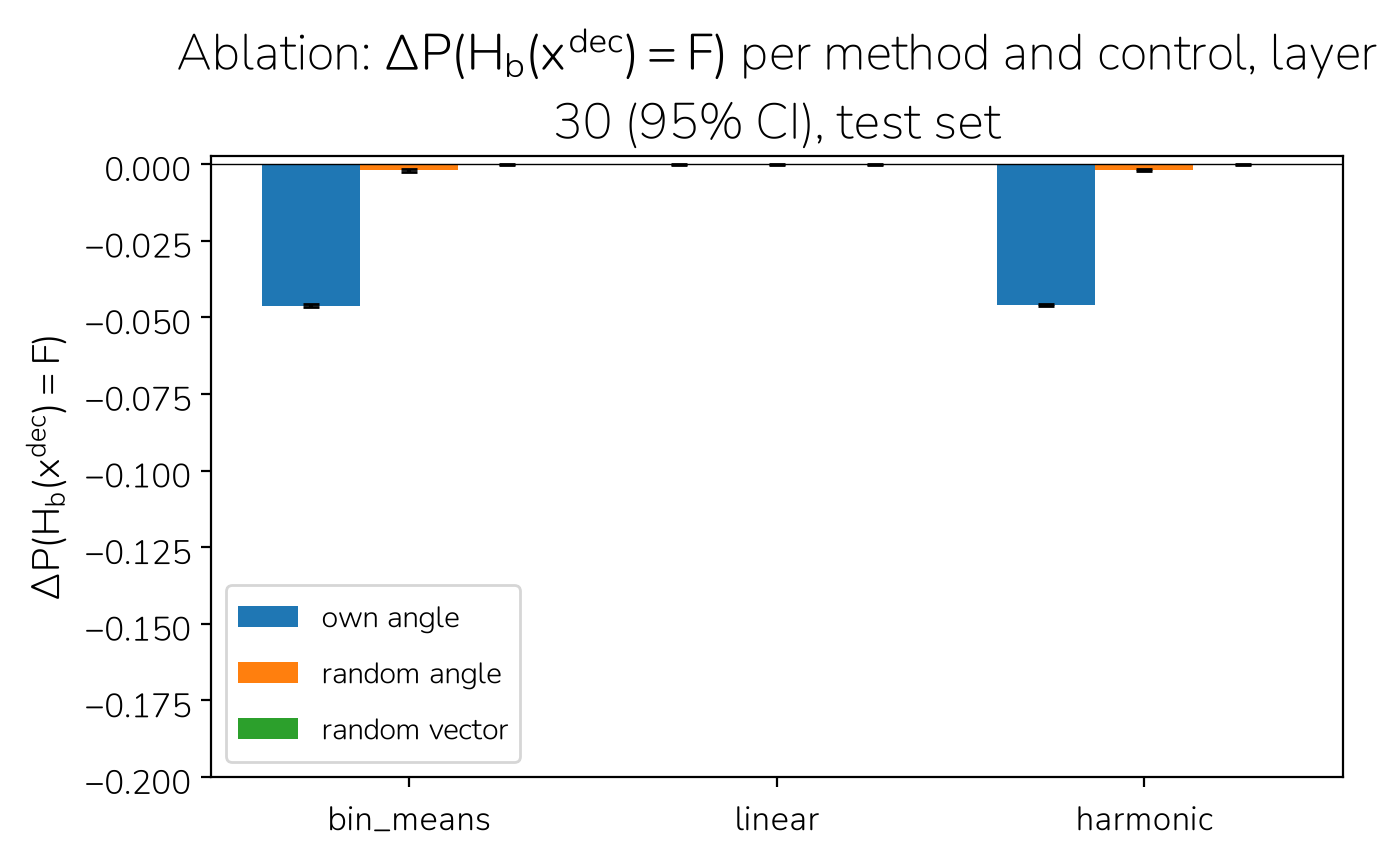

In [5]:
HYDROPHOBIC, HYDROPHILIC = "ACGILMFPWYV", "STNQHDEKR"  # sign of the Eisenberg consensus scale
EDITS = [method + control for method in ["bin_means", "linear", "harmonic"]  # the three approximations of the latent (notebook 3)
         for control in ["", " | random angle", " | random vector"]]
METRICS = ["decoded_residue_agrees_with_face", "probability_mass_agrees_with_face"]
N_BOOT = 2000
boot_rng = np.random.default_rng(1)

# per row: does the decoded residue's class agree with the face, and the probability mass on the class that agrees with it
log_probs = results["aa_log_probs"].cast(pl.Array(pl.Float32, len(AA))).to_numpy()  # (rows, 20), amino acids in the order of AA
in_hydrophobic = np.array([a in HYDROPHOBIC for a in AA])
inner_face = (results["helix_face"].abs() <= 90).to_numpy()  # F_i: inner face, |theta| <= 90 degrees
m = results.drop("aa_log_probs").with_columns(
    inner_face=pl.Series(inner_face),
    decoded_residue_agrees_with_face=(pl.col("top1_aa").is_in(list(HYDROPHOBIC)) == pl.Series(inner_face)).cast(pl.Float64),
    probability_mass_agrees_with_face=np.where(inner_face, np.exp(log_probs[:, in_hydrophobic]).sum(1), np.exp(log_probs[:, ~in_hydrophobic]).sum(1)),
    true_residue_agrees_with_face=(pl.col("aa").is_in(list(HYDROPHOBIC)) == pl.Series(inner_face)).cast(pl.Float64),
)
before = m.filter(pl.col("edit") == "none").select("accession", "i", "layer", *[pl.col(x).alias(f"{x} before") for x in METRICS])
changes = (
    m.filter(pl.col("edit").is_in(EDITS))
    .select("accession", "i", "layer", "edit", *METRICS)
    .join(before, on=["accession", "i", "layer"])
    .with_columns(*[(pl.col(x) - pl.col(f"{x} before")).alias(f"{x} change") for x in METRICS])
)

# bootstrap: resampling proteins
proteins = results["accession"].unique().sort()
weights = boot_rng.multinomial(len(proteins), np.full(len(proteins), 1 / len(proteins)), size=N_BOOT).astype(np.float64)  # (N_BOOT, proteins)


def mean_and_boot(frame, column):
    """Mean of `column` over residues, and its bootstrap values (resampling proteins)."""
    per_protein = pl.DataFrame({"accession": proteins}).join(
        frame.group_by("accession").agg(s=pl.col(column).sum(), n=pl.len()), on="accession", how="left").fill_null(0)
    s, n = per_protein["s"].to_numpy(), per_protein["n"].to_numpy()
    return s.sum() / n.sum(), (weights @ s) / (weights @ n)


def ci(value, boot):
    return value, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


rows = []
for layer in LAYERS:
    for metric in METRICS:
        unedited = m.filter((pl.col("layer") == layer) & (pl.col("edit") == "none"))
        stats = {"before": mean_and_boot(unedited, metric), "true residues": mean_and_boot(unedited, "true_residue_agrees_with_face")}
        for edit in EDITS:
            stats[f"change: {edit}"] = mean_and_boot(changes.filter((pl.col("layer") == layer) & (pl.col("edit") == edit)), f"{metric} change")
        for name, (value, boot) in stats.items():
            rows.append({"layer": layer, "metric": metric, "statistic": name, **dict(zip(["value", "ci_low", "ci_high"], ci(value, boot)))})
face_agreement = pl.DataFrame(rows)

pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)
pl.Config.set_fmt_str_lengths(45)
for layer in LAYERS:
    display(face_agreement.filter(pl.col("layer") == layer).with_columns(pl.col("value", "ci_low", "ci_high").round(4)))

# Change of decoded_residue_agrees_with_face per method and control, layer 30 (95% CI from the protein bootstrap above)
METHODS, CONTROLS = ["bin_means", "linear", "harmonic"], ["", " | random angle", " | random vector"]
fig, ax = plt.subplots(figsize=(7, 4.5))
width = 0.8 / len(CONTROLS)
for j, control in enumerate(CONTROLS):
    rows = [face_agreement.filter((pl.col("layer") == 30) & (pl.col("metric") == "decoded_residue_agrees_with_face")
                                  & (pl.col("statistic") == f"change: {method}{control}")).row(0, named=True) for method in METHODS]
    values = np.array([r["value"] for r in rows])
    errors = np.array([[r["value"] - r["ci_low"], r["ci_high"] - r["value"]] for r in rows]).T
    ax.bar(np.arange(len(METHODS)) + (j - (len(CONTROLS) - 1) / 2) * width, values, width, yerr=errors, capsize=3,
           label=control.removeprefix(" | ") or "own angle")
ax.set_xticks(np.arange(len(METHODS)), METHODS)
ax.axhline(0, color="black", linewidth=0.5)
ax.set_ylabel(r"$\Delta P(H_b(x^{dec}) = F)$")
ax.set_ylim(bottom=-0.2)
ax.legend(fontsize="small")
ax.set_title(r"Ablation: $\Delta P(H_b(x^{dec}) = F)$ per method and control, layer 30 (95% CI), test set")
plt.tight_layout()
plt.show()

### Hydrophobicity and helix face as continous variables
- Instead of treating hydrophobicity as a binary label, we can account for the fact that different amino-acids have different hydrophobicities, as given by the previously mentioned Eisenberg consensus scale. Works on hydrophobic moment also leads us to expect that hydrophobicity and $\cos {\theta}$ should be strongly correlated. If this correlation is lost for predicted residues after our ablation, that will add to the evidence that this subspace of the model is used to predict hydrophobic or hydrophilic residues.

- We'll measure pearson correlation, spearman correlation, and the OLS slope between $H$ and $\cos (\theta)$
- Bootstrap conf

In [6]:
from scipy.stats import rankdata

EISENBERG = dict(zip("ARNDCQEGHILKMFPSTWYV", [0.62, -2.53, -0.78, -0.90, 0.29, -0.85, -0.74, 0.48, -0.40, 1.38,
                                                1.06, -1.50, 0.64, 1.19, 0.12, -0.18, -0.05, 0.81, 0.26, 1.08]))
EDITS = [method + control for method in ["bin_means", "linear", "harmonic"] for control in ["", " | random angle", " | random vector"]]

# one row per residue, layer and edit; the same residue order in every (layer, edit)
h = (
    results.select("accession", "i", "layer", "edit", "aa", "helix_face")
    .with_columns(h_pred=np.exp(results["aa_log_probs"].cast(pl.Array(pl.Float32, len(AA))).to_numpy()) @ np.array([EISENBERG[a] for a in AA]))
    .filter(pl.col("aa").is_in(list(EISENBERG)))
    .sort("layer", "edit", "accession", "i")
    .with_columns(h_true=pl.col("aa").replace_strict(EISENBERG), cos_face=pl.col("helix_face").radians().cos())
)


def statistics(x, y):
    """Pearson r, Spearman rho and the least-squares slope of y on x."""
    pearson = np.corrcoef(x, y)[0, 1]
    spearman = np.corrcoef(rankdata(x), rankdata(y))[0, 1]
    slope = np.cov(x, y)[0, 1] / np.var(x, ddof=1)
    return np.array([pearson, spearman, slope])


METRICS = ["pearson", "spearman", "slope"]


def weighted_statistics(sums, w):
    """Pearson r and slope from per-protein sums (n, x, y, xx, yy, xy), with protein weights w (bootstrap, ...)."""
    n, x, y, xx, yy, xy = (w @ s for s in sums)
    cov, var_x, var_y = xy / n - x * y / n**2, xx / n - (x / n) ** 2, yy / n - (y / n) ** 2
    return cov / np.sqrt(var_x * var_y), cov / var_x


rows = []
for layer in LAYERS:
    unedited = h.filter((pl.col("layer") == layer) & (pl.col("edit") == "none"))
    x = unedited["cos_face"].to_numpy()
    series = {"before": unedited["h_pred"].to_numpy(), "true residues": unedited["h_true"].to_numpy(),
              **{edit: h.filter((pl.col("layer") == layer) & (pl.col("edit") == edit))["h_pred"].to_numpy() for edit in EDITS}}

    # bootstrap: resample proteins with multinomial weights, the same weights for every statistic, so the changes are paired.
    # Pearson and slope are exact functions of per-protein sums; Spearman is the Pearson r of the ranks in the full sample
    # (the ranks are not computed again in each bootstrap sample)
    proteins, protein_of_residue = np.unique(unedited["accession"].to_numpy(), return_inverse=True)
    weights = boot_rng.multinomial(len(proteins), np.full(len(proteins), 1 / len(proteins)), size=N_BOOT).astype(np.float64)

    def per_protein_sums(a, b):
        return [np.bincount(protein_of_residue, v, len(proteins)) for v in [np.ones_like(a), a, b, a * a, b * b, a * b]]

    boot = {}
    for name, y in series.items():
        pearson, slope = weighted_statistics(per_protein_sums(x, y), weights)
        spearman, _ = weighted_statistics(per_protein_sums(rankdata(x), rankdata(y)), weights)
        boot[name] = np.column_stack([pearson, spearman, slope])

    estimate = {name: statistics(x, y) for name, y in series.items()}
    for k, metric in enumerate(METRICS):
        for name in ["before", "true residues"]:
            rows.append({"layer": layer, "metric": metric, "statistic": name, "value": estimate[name][k],
                         "ci_low": np.percentile(boot[name][:, k], 2.5), "ci_high": np.percentile(boot[name][:, k], 97.5)})
        for edit in EDITS:
            change = boot[edit][:, k] - boot["before"][:, k]
            rows.append({"layer": layer, "metric": metric, "statistic": f"change: {edit}", "value": estimate[edit][k] - estimate["before"][k],
                         "ci_low": np.percentile(change, 2.5), "ci_high": np.percentile(change, 97.5)})
face_correlation = pl.DataFrame(rows)

for layer in LAYERS:
    display(face_correlation.filter(pl.col("layer") == layer).with_columns(pl.col("value", "ci_low", "ci_high").round(4)))

layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
28,"""pearson""","""before""",0.2199,0.2176,0.2221
28,"""pearson""","""true residues""",0.182,0.1799,0.1841
28,"""pearson""","""change: bin_means""",-0.0445,-0.0448,-0.0443
28,"""pearson""","""change: bin_means | random angle""",-0.0001,-0.0003,0.0001
28,"""pearson""","""change: bin_means | random vector""",0.0,-0.0001,0.0001
28,"""pearson""","""change: linear""",-0.0001,-0.0002,-0.0001
28,"""pearson""","""change: linear | random angle""",0.0001,0.0001,0.0001
28,"""pearson""","""change: linear | random vector""",-0.0,-0.0,0.0
28,"""pearson""","""change: harmonic""",-0.0441,-0.0444,-0.0439


layer,metric,statistic,value,ci_low,ci_high
i64,str,str,f64,f64,f64
30,"""pearson""","""before""",0.2199,0.2176,0.2222
30,"""pearson""","""true residues""",0.182,0.1799,0.1842
30,"""pearson""","""change: bin_means""",-0.1222,-0.1228,-0.1217
30,"""pearson""","""change: bin_means | random angle""",-0.0039,-0.0042,-0.0035
30,"""pearson""","""change: bin_means | random vector""",-0.0,-0.0001,0.0001
30,"""pearson""","""change: linear""",0.0001,0.0001,0.0002
30,"""pearson""","""change: linear | random angle""",-0.0,-0.0001,0.0
30,"""pearson""","""change: linear | random vector""",0.0,0.0,0.0
30,"""pearson""","""change: harmonic""",-0.1221,-0.1227,-0.1216


# Looking for the tail end of the distribution
- So far, we have some indication that ESM might contain information on helix face angle, and that the network might be reading from it in order to predict hydrophobic or hydrophilic amino-acids. However, we also saw that the top predicted residue is affected most of the time, and the average effect is significant under our bootstrap conditions, yet of low magnitude. We might wonder whether residues with high prediction error share a common pattern: for instance, it might be that this angle is most important in predictions for residues within alpha helices that have high correlations between $\cos(\theta)$ and $H$. Are there subgroups for which error is greater with high specificity, or small subgroups which account for a large percentage of the error ?
- Care must be taken when choosing the error metric. Baseline top1 accuracy is 0.4379 for our dataset, so many predictions on swissprot's own data (which was most likely all in ESM's training set) are wrong here. The (arithmetic) mean likelihood for the correct token sits around 30% for this model and the mean log-likelihood at around -1.7

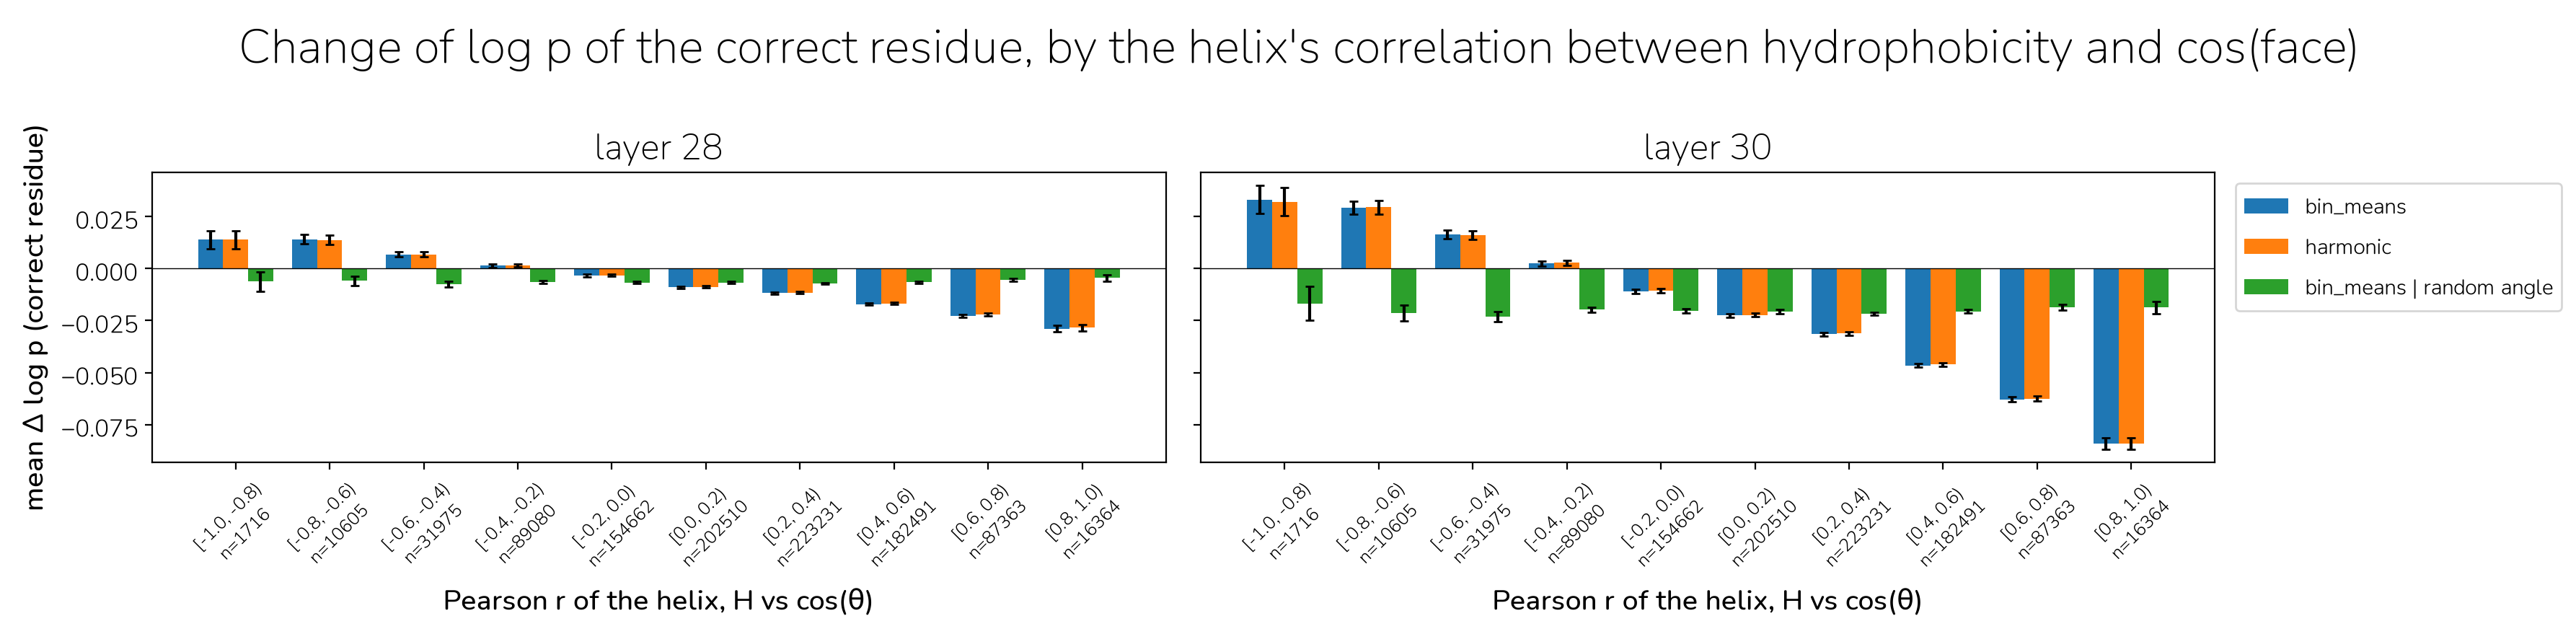

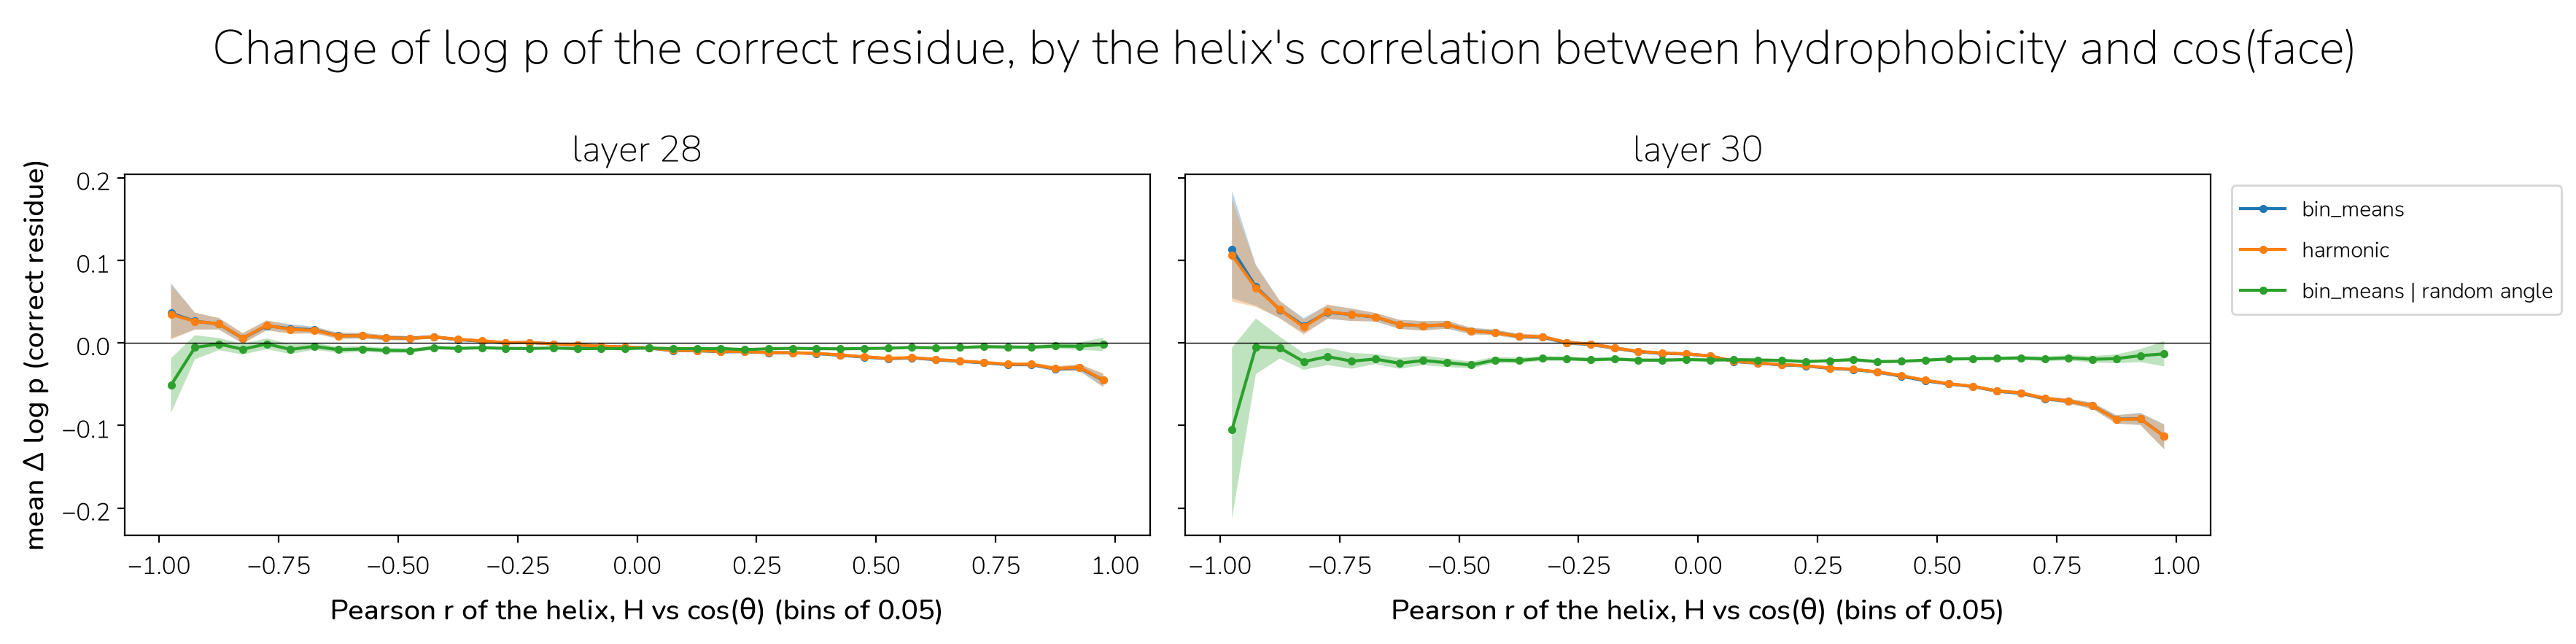

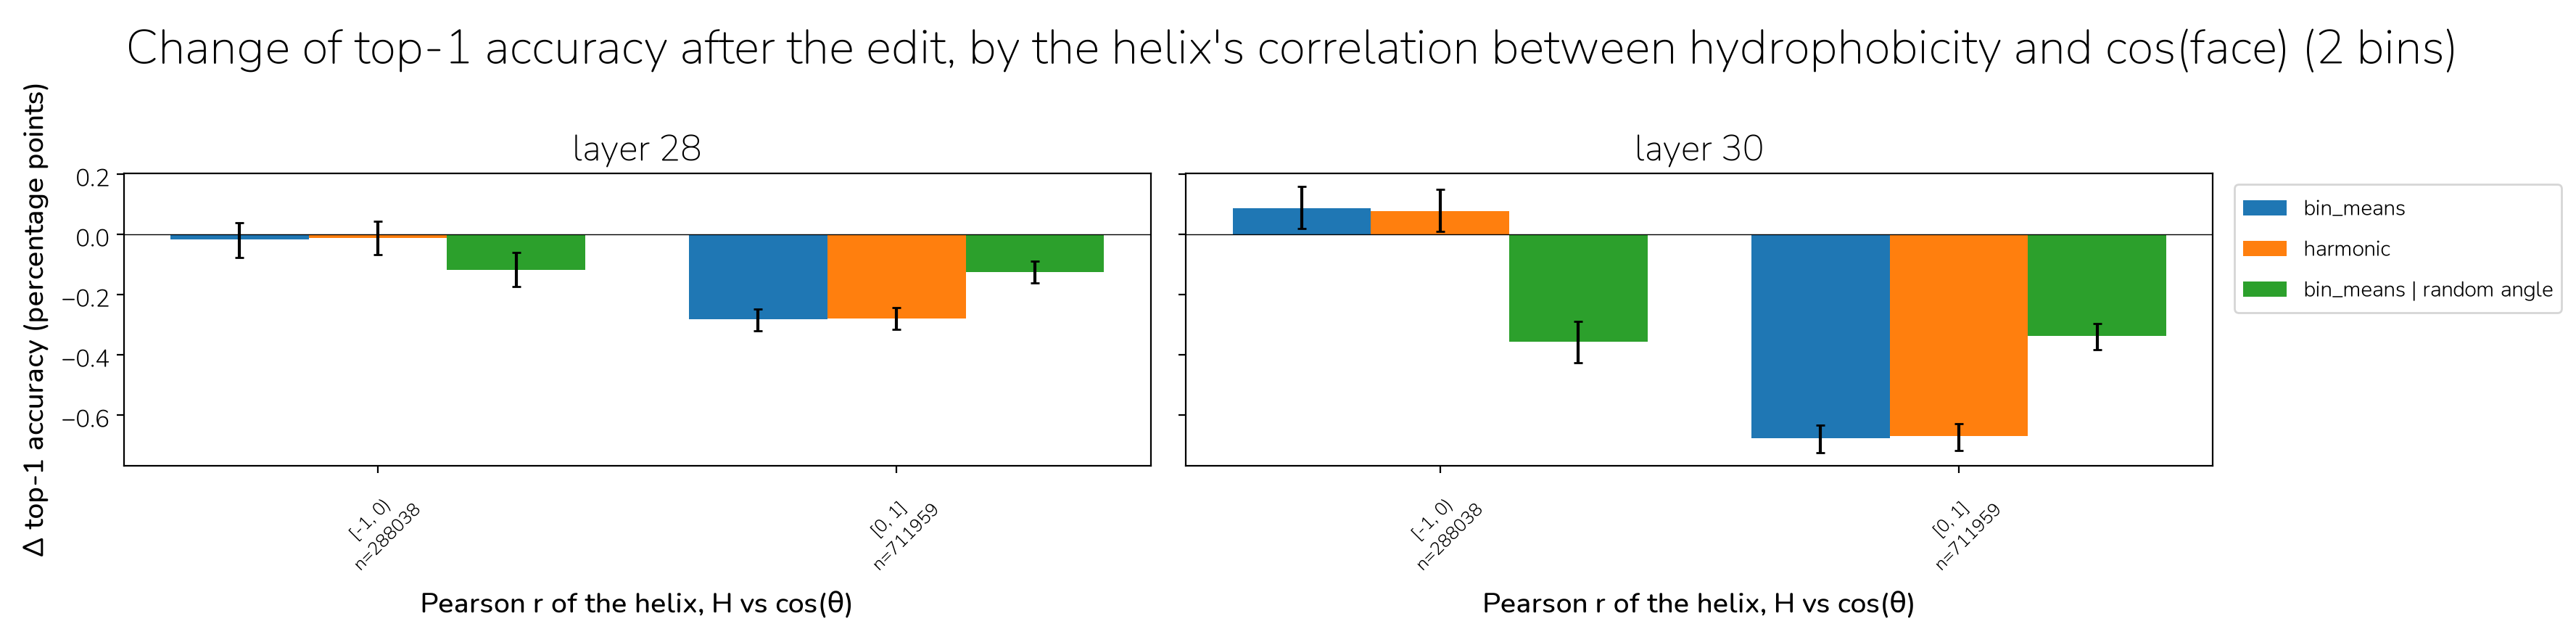

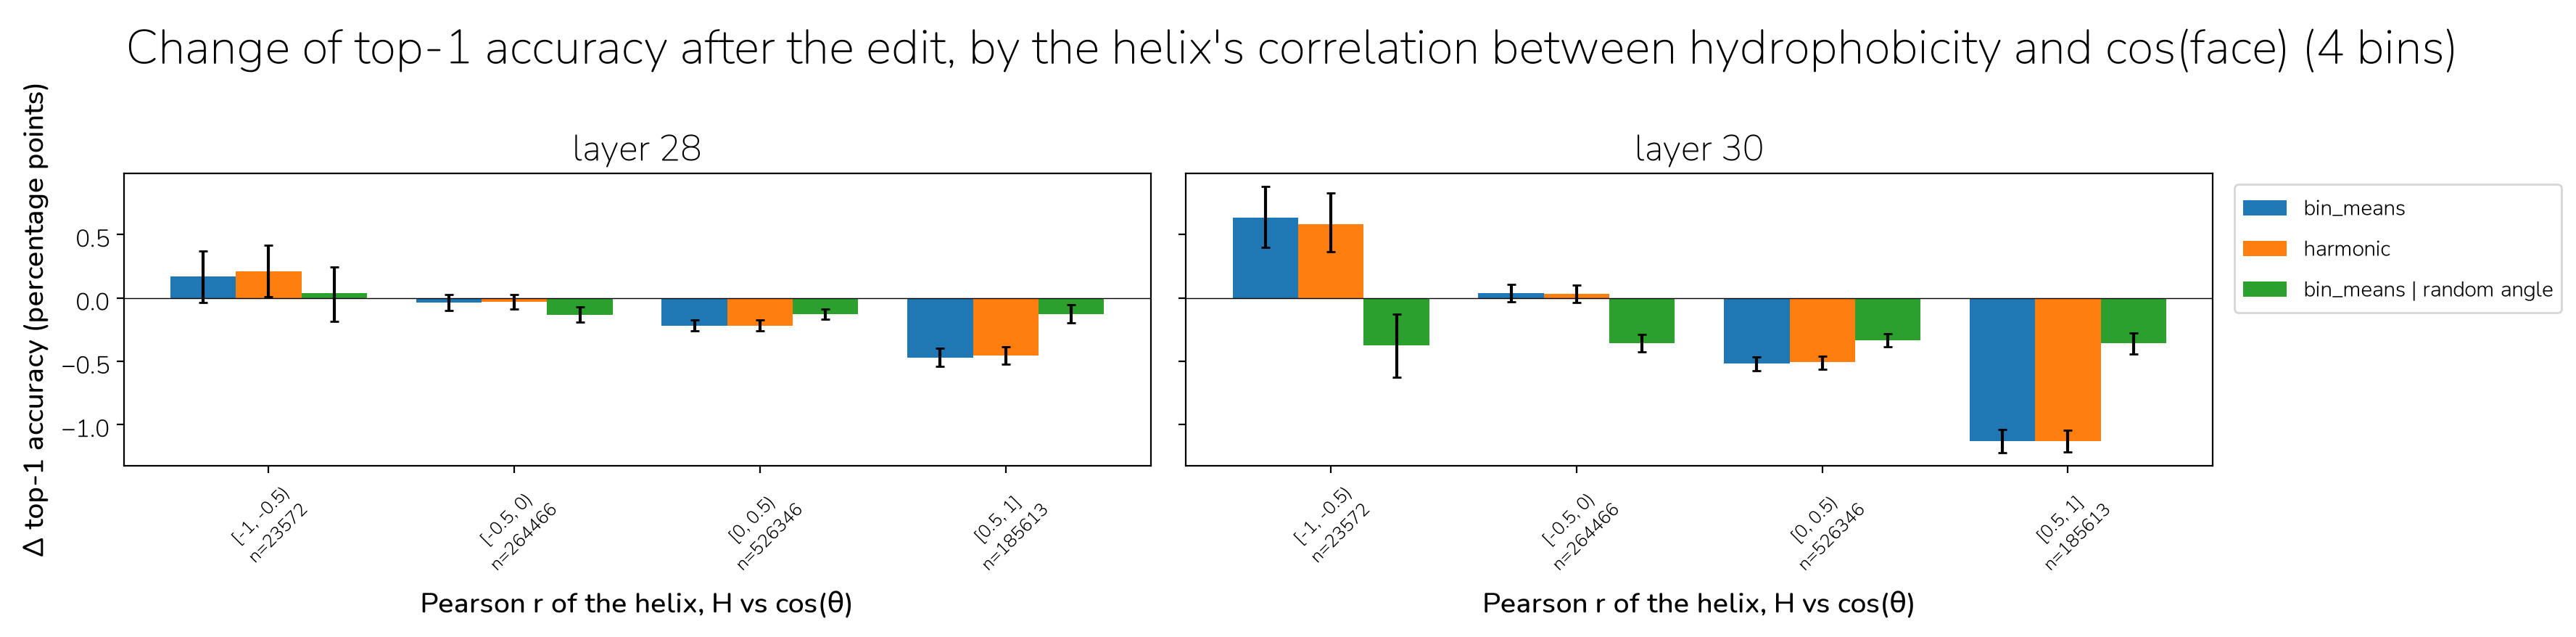

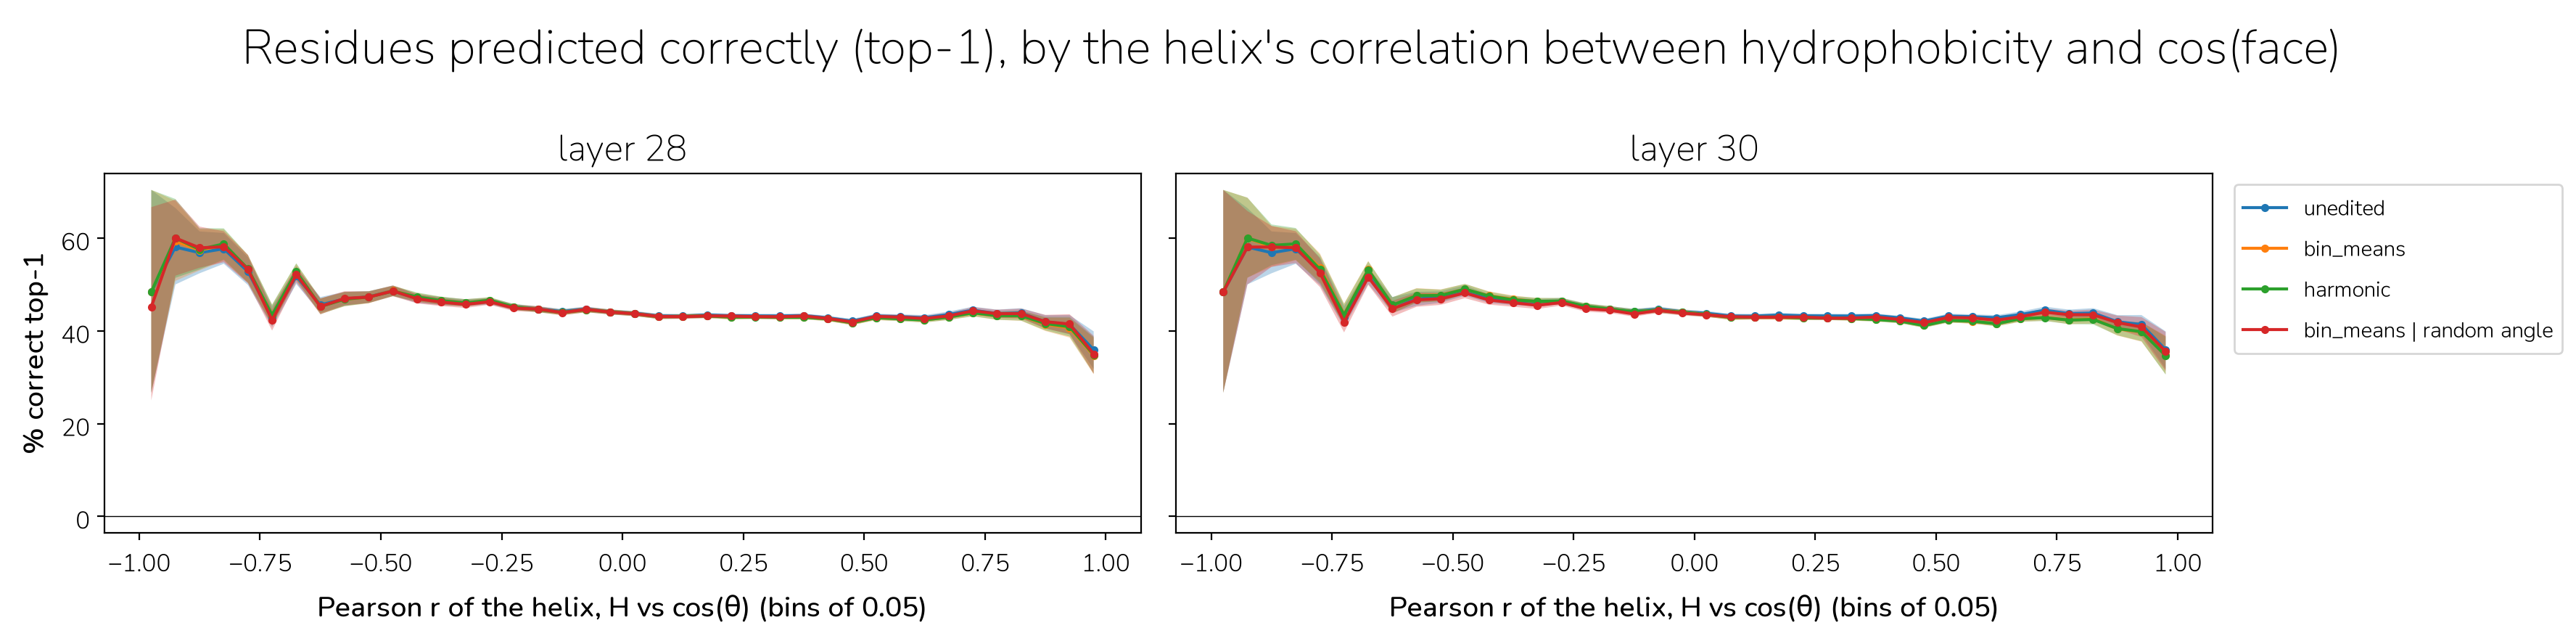

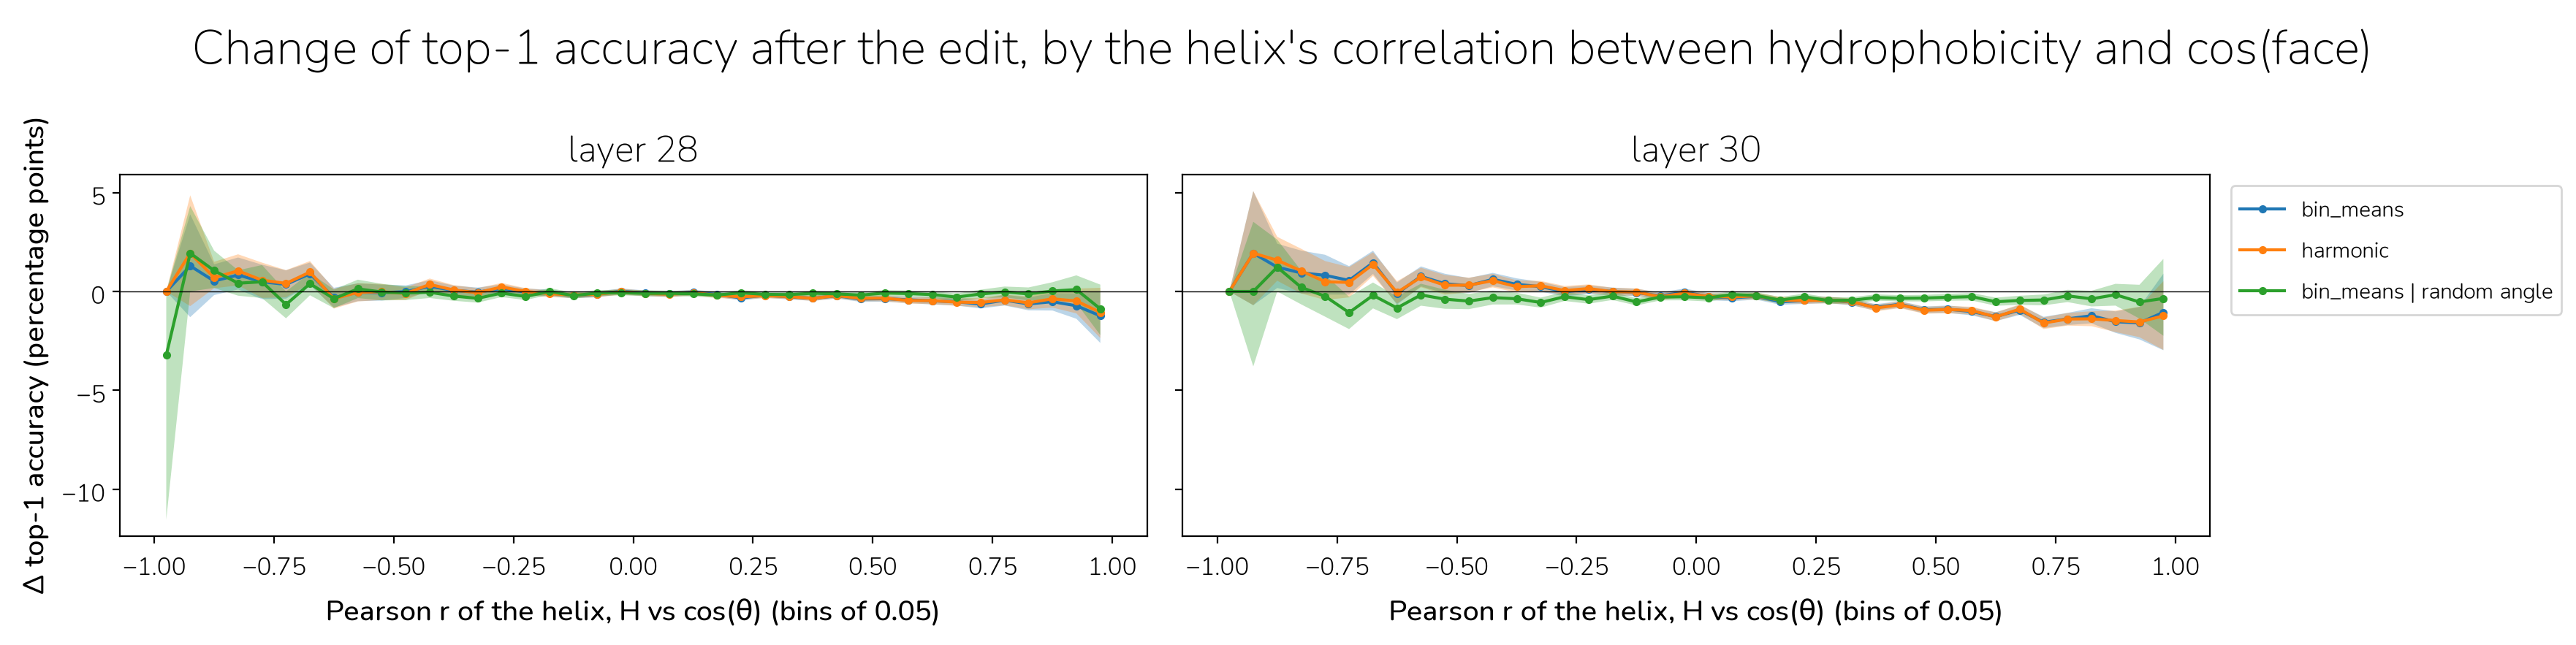

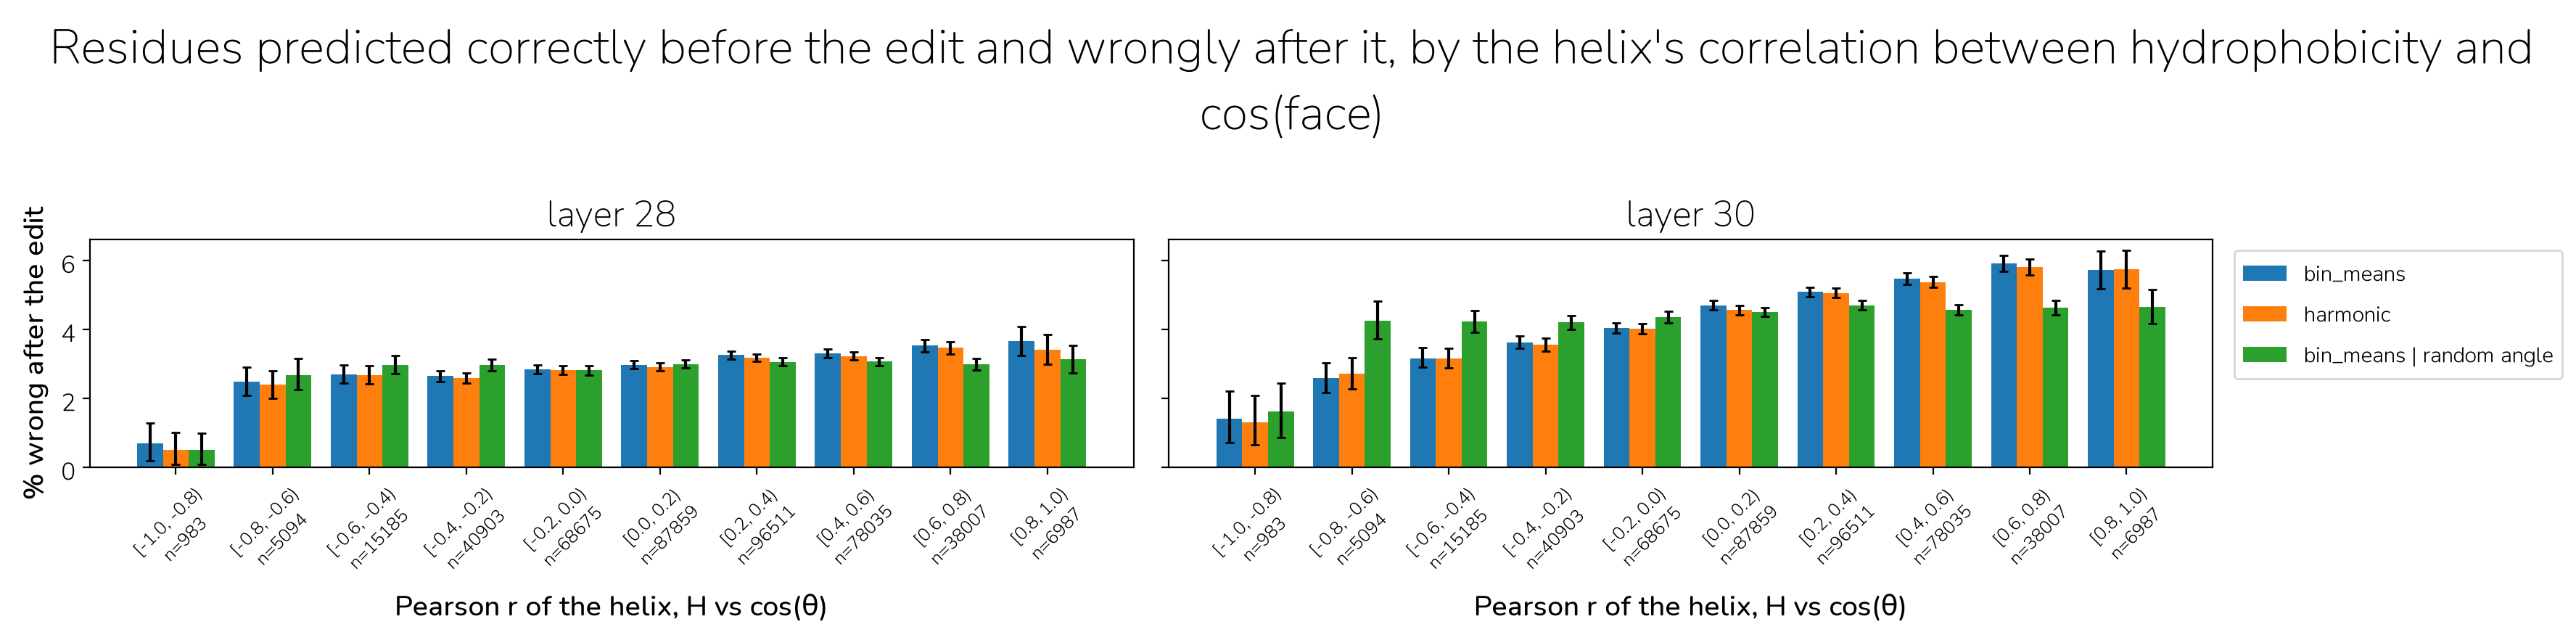

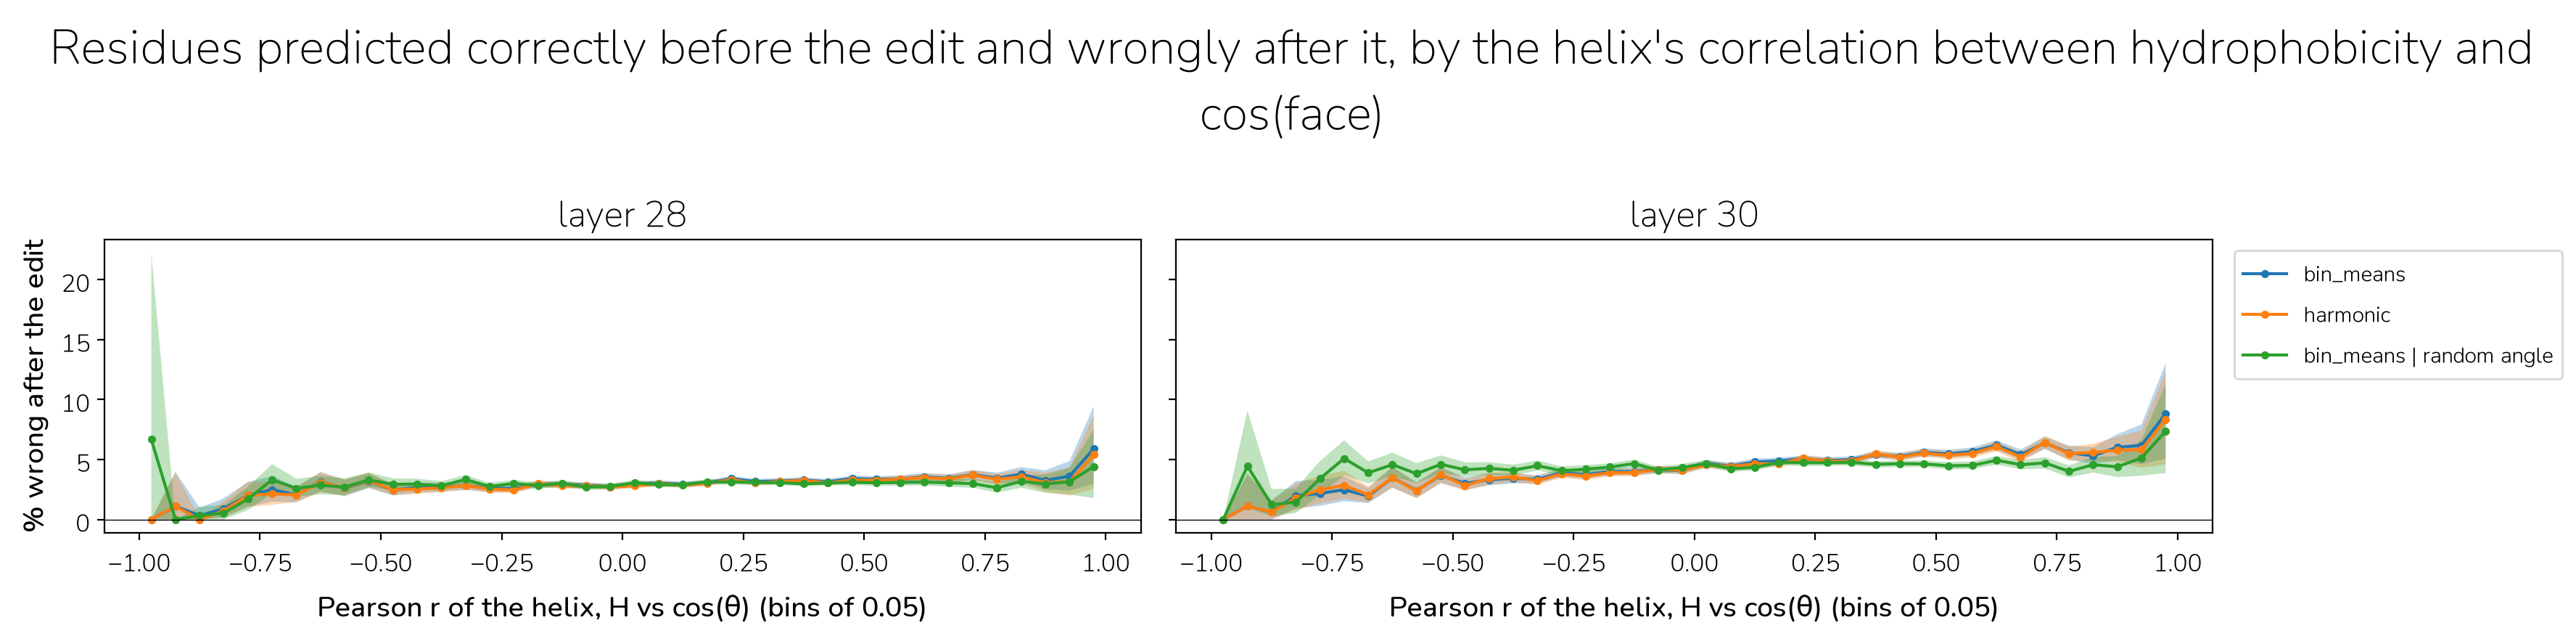

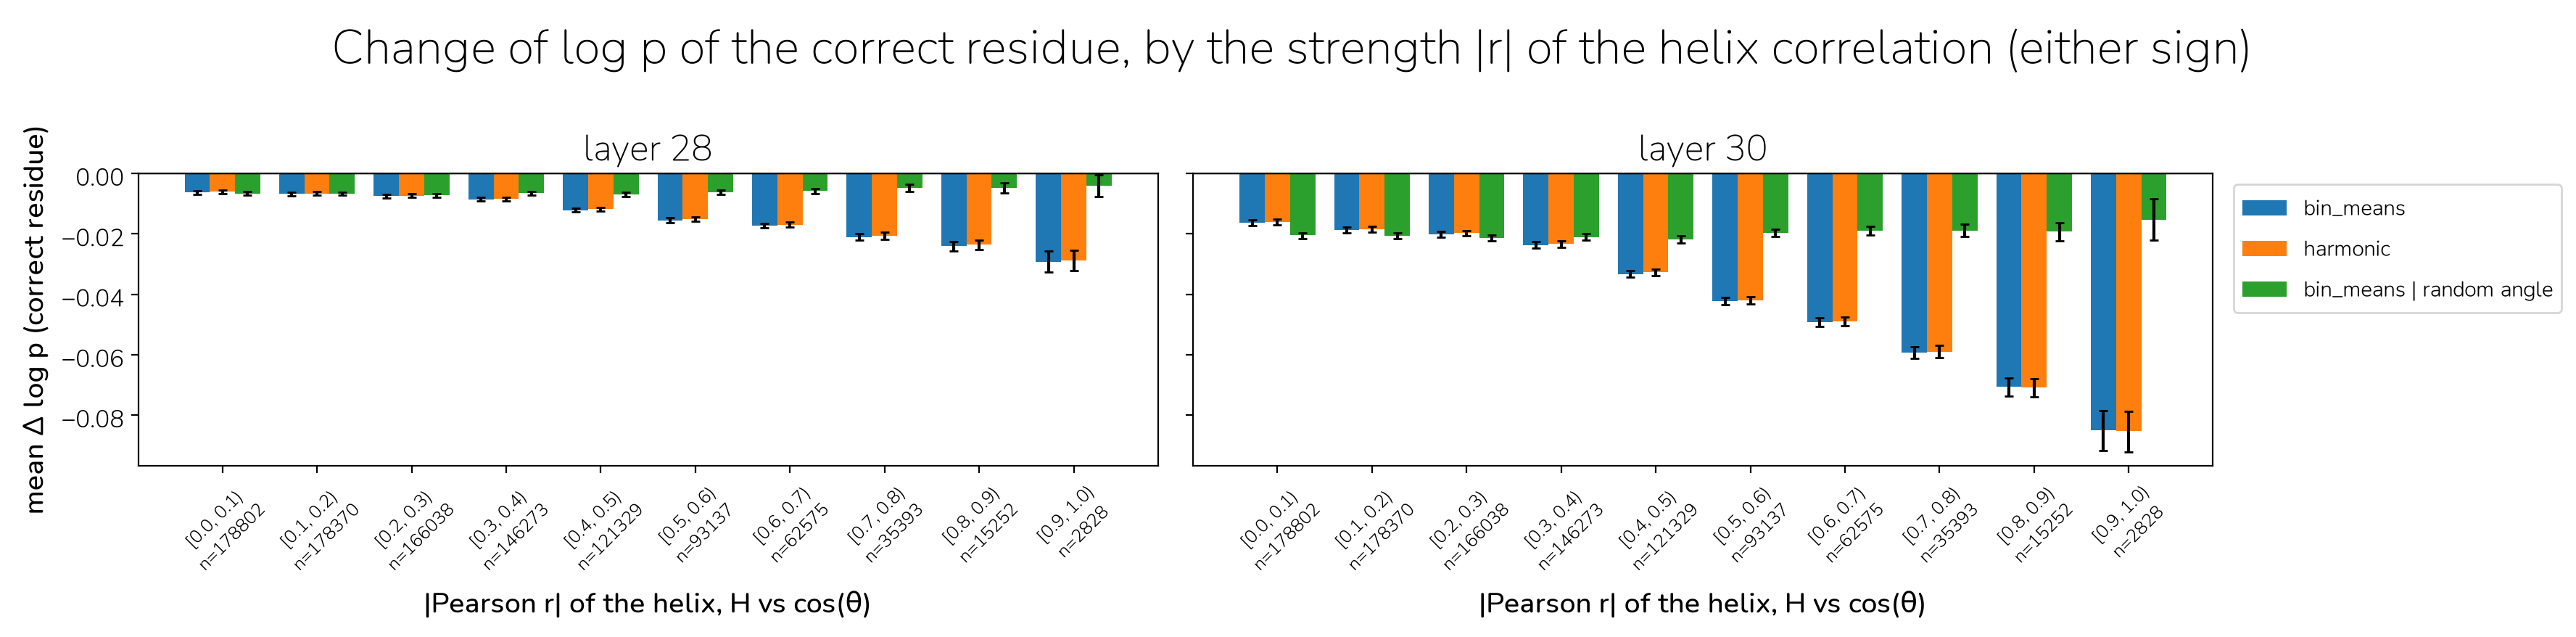

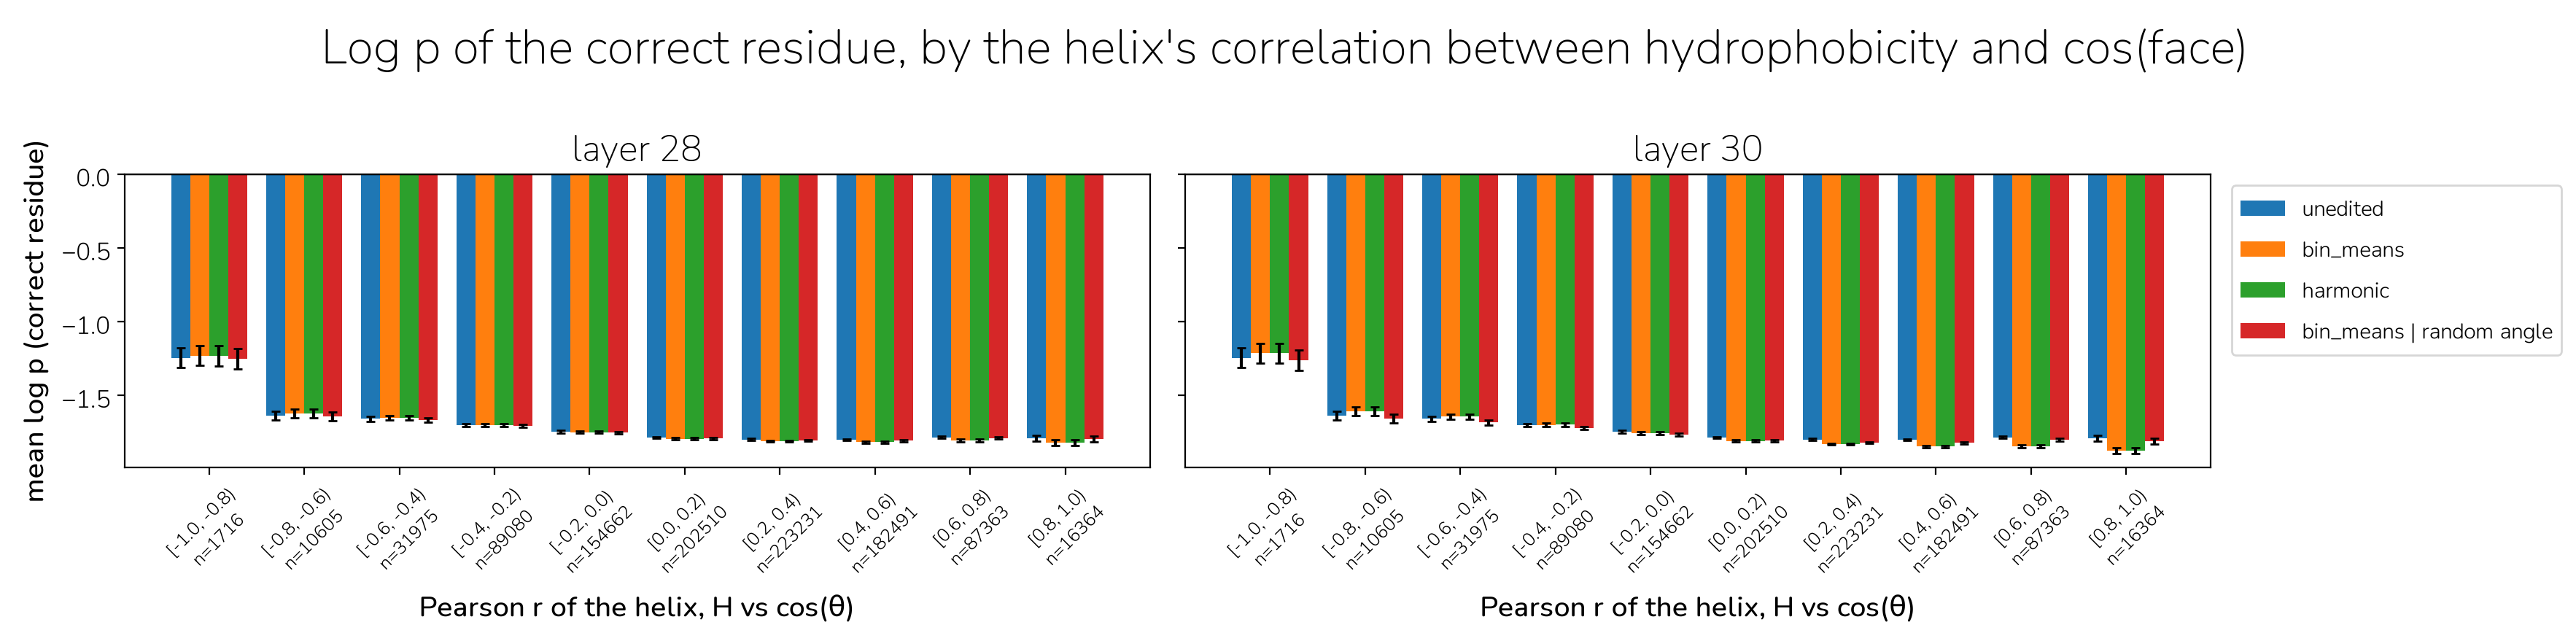

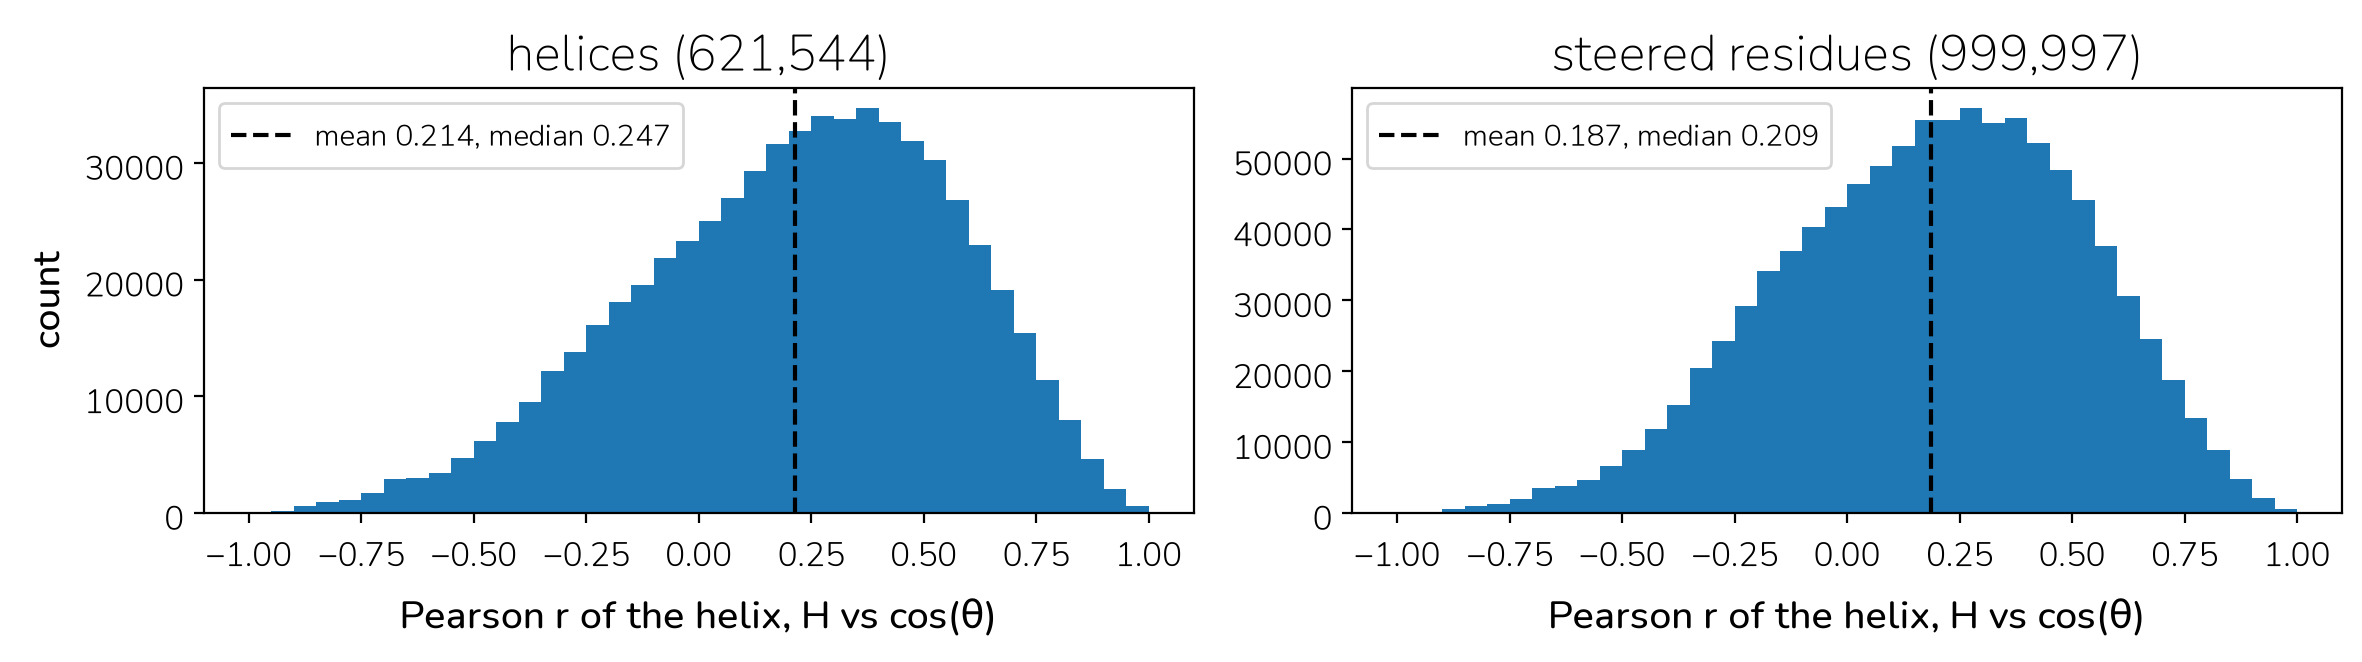

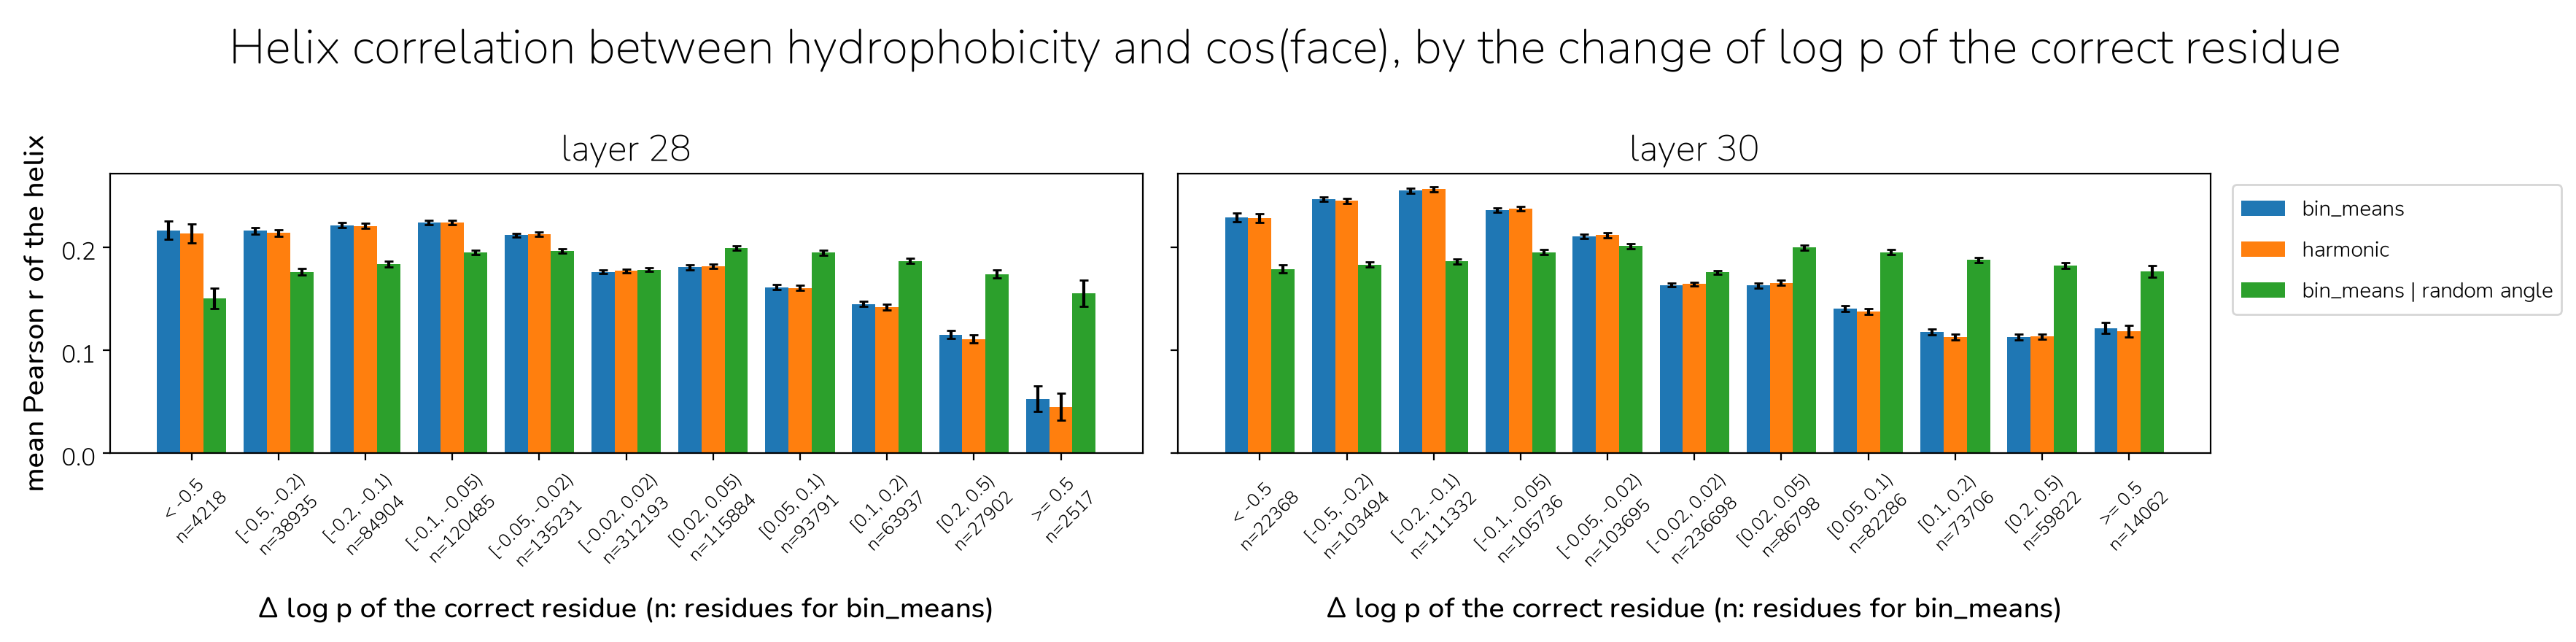

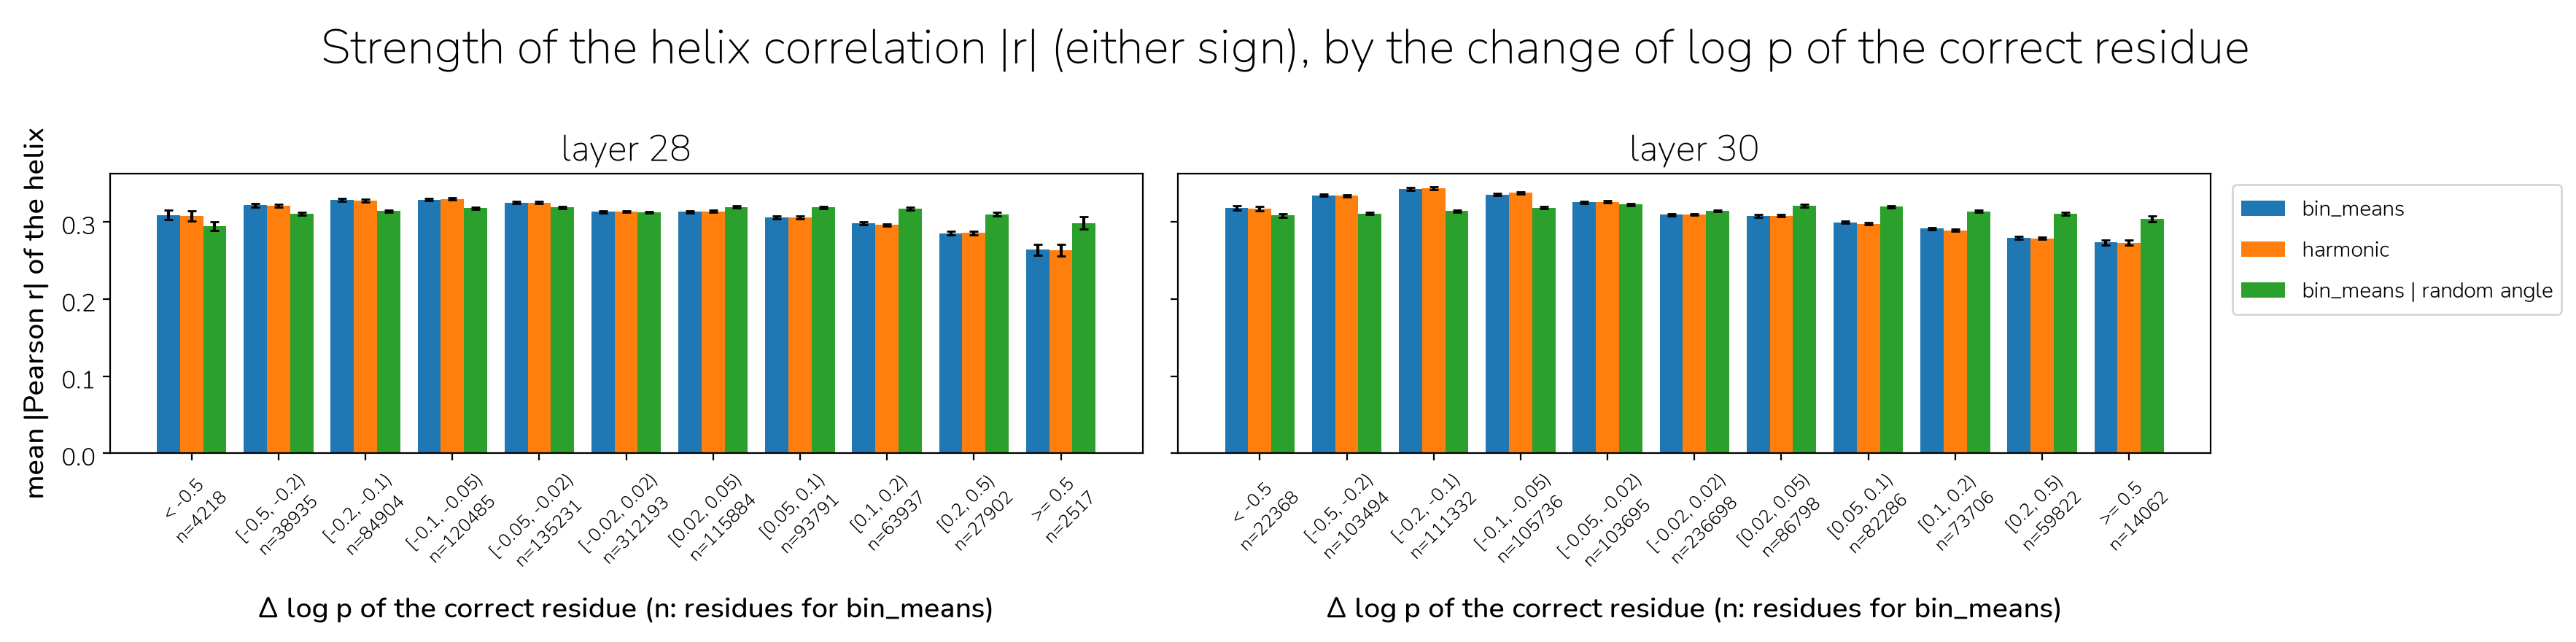

In [7]:
from biomanifolds.labels import af2_structure_labels

# Plot: bar plot for mean decrease in correct residue LL (y) by pearson(H, \cos(\theta))
# 2nd plot: same but for LL instead of \Delta LL
R_EDGES = np.linspace(-1, 1, 11)  # bins of the per-helix Pearson r
R_BINS = [f"[{low:.1f}, {high:.1f})" for low, high in zip(R_EDGES[:-1], R_EDGES[1:])]
ABS_R_EDGES = np.linspace(0, 1, 11)  # bins of |r|
ABS_R_BINS = [f"[{low:.1f}, {high:.1f})" for low, high in zip(ABS_R_EDGES[:-1], ABS_R_EDGES[1:])]
PLOT_EDITS = ["bin_means", "harmonic", "bin_means | random angle"]
COARSE_EDGES = {2: [0.0], 4: [-0.5, 0.0, 0.5]}  # inner edges of the coarse bins of r
COARSE_BINS = {2: ["[-1, 0)", "[0, 1]"], 4: ["[-1, -0.5)", "[-0.5, 0)", "[0, 0.5)", "[0.5, 1]"]}
DELTA_EDGES = [-0.5, -0.2, -0.1, -0.05, -0.02, 0.02, 0.05, 0.1, 0.2, 0.5]  # bins of the change of log p
DELTA_BINS = ["< -0.5"] + [f"[{low}, {high})" for low, high in zip(DELTA_EDGES[:-1], DELTA_EDGES[1:])] + [">= 0.5"]

# every helix of the proteins in the results: a helix is a run of residues with a helix face (always >= 7 residues)
helix_residues = (
    af2_structure_labels.load_labels(["accession", "i", "helix_face", "pos_in_seg"])
    .filter(pl.col("helix_face").is_not_null())
    .join(results.select("accession").unique().lazy(), on="accession")
    .join(sequences.lazy(), on="accession")
    .with_columns(helix_start=pl.col("i") - pl.col("pos_in_seg"), aa=pl.col("sequence").str.slice(pl.col("i"), 1))
    .drop("sequence")
    .filter(pl.col("aa").is_in(list(EISENBERG)))
    .collect(engine="streaming")
)
# r of each helix: Pearson correlation between the Eisenberg hydrophobicity of its true residues and cos(face)
helix_r = helix_residues.group_by("accession", "helix_start").agg(
    helix_r=pl.corr(pl.col("aa").replace_strict(EISENBERG, return_dtype=pl.Float64), pl.col("helix_face").radians().cos()))

# the helix (and its r) of every steered residue
per_residue = (
    results.filter(pl.col("edit").is_in(["none", *PLOT_EDITS])).select("accession", "i", "layer", "edit", "log_likelihood", "top1_correct")
    .join(helix_residues.select("accession", "i", "helix_start"), on=["accession", "i"])
    .join(helix_r, on=["accession", "helix_start"])
    .join(results.filter(pl.col("edit") == "none").select("accession", "i", "layer", ll_unedited="log_likelihood", top1_unedited="top1_correct"), on=["accession", "i", "layer"])
    .with_columns(delta_ll=pl.col("log_likelihood") - pl.col("ll_unedited"),
                  correct=pl.col("top1_correct").cast(pl.Float64) * 100,  # % of residues predicted correctly (top-1)
                  delta_correct=(pl.col("top1_correct").cast(pl.Float64) - pl.col("top1_unedited").cast(pl.Float64)) * 100,  # change, percentage points
                  correct_to_wrong=(~pl.col("top1_correct")).cast(pl.Float64) * 100,  # %, used only for residues correct before the edit
                  r_bin=pl.col("helix_r").bin_intervals(R_EDGES[1:-1].tolist(), labels=R_BINS).cast(pl.String))
    .with_columns(delta_bin=pl.col("delta_ll").bin_intervals(DELTA_EDGES, labels=DELTA_BINS).cast(pl.String),
                  abs_helix_r=pl.col("helix_r").abs(),
                  coarse2_bin=pl.col("helix_r").bin_intervals(COARSE_EDGES[2], labels=COARSE_BINS[2]).cast(pl.String),
                  coarse4_bin=pl.col("helix_r").bin_intervals(COARSE_EDGES[4], labels=COARSE_BINS[4]).cast(pl.String),
                  abs_r_bin=pl.col("helix_r").abs().bin_intervals(ABS_R_EDGES[1:-1].tolist(), labels=ABS_R_BINS).cast(pl.String))
    .filter(pl.col("helix_r").is_not_nan())  # helices of a single amino-acid class value have no r
)


def bar_plot(column, series, ylabel, title, bin_column="r_bin", bins=R_BINS, xlabel="Pearson r of the helix, H vs cos(θ)", data=None):
    """Bars of the mean of `column` per bin of `bin_column`, one bar per (name, edit) in `series`, one subplot per layer;
    95% CI from the protein bootstrap. n: the residues in the bin, for the first edit in `series`. data: the residues (default: all)."""
    data = per_residue if data is None else data
    fig, axes = plt.subplots(1, len(LAYERS), figsize=(18, 4.5), sharey=True)
    width = 0.8 / len(series)
    for ax, layer in zip(axes, LAYERS):
        counts = data.filter((pl.col("layer") == layer) & (pl.col("edit") == series[0][1]))[bin_column].value_counts()
        counts = dict(zip(counts[bin_column], counts["count"]))
        for k, (name, edit) in enumerate(series):
            values, errors = [], []
            for b in bins:
                frame = data.filter((pl.col("layer") == layer) & (pl.col("edit") == edit) & (pl.col(bin_column) == b))
                if len(frame) == 0:
                    values.append(np.nan), errors.append((0, 0))
                    continue
                value, boot = mean_and_boot(frame, column)
                low, high = np.nanpercentile(boot, [2.5, 97.5])
                values.append(value), errors.append((value - low, high - value))
            ax.bar(np.arange(len(bins)) + (k - (len(series) - 1) / 2) * width, values, width, yerr=np.array(errors).T, capsize=2, label=name)
        ax.set_xticks(np.arange(len(bins)), [f"{b}\nn={counts.get(b, 0)}" for b in bins], rotation=45, fontsize="x-small")
        ax.axhline(0, color="black", linewidth=0.5)
        ax.set_title(f"layer {layer}")
        ax.set_xlabel(xlabel)
    axes[0].set_ylabel(ylabel)
    axes[-1].legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.01, 1))  # outside, to the right
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


bar_plot("delta_ll", [(edit, edit) for edit in PLOT_EDITS], "mean Δ log p (correct residue)",
         "Change of log p of the correct residue, by the helix's correlation between hydrophobicity and cos(face)")

# The same with finer bins of r (width 0.05): one line per edit, the 95% CI as a band
FINE_EDGES = np.linspace(-1, 1, 41)


def line_plot(column, series, ylabel, title, data=None, layers=LAYERS):
    """Mean of `column` per r bin of width 0.05, one line per (name, edit) in `series`, one subplot per layer;
    95% CI from the protein bootstrap as a band. data: the residues (default: all)."""
    data = per_residue if data is None else data
    groups = data.select("accession", "layer", "edit", "helix_r", column).with_columns(
        fine_bin=pl.col("helix_r").bin_intervals(FINE_EDGES[1:-1].tolist(), labels=False)).partition_by("layer", "edit", "fine_bin", as_dict=True)
    centres = (FINE_EDGES[:-1] + FINE_EDGES[1:]) / 2
    fig, axes = plt.subplots(1, len(layers), figsize=(9 * len(layers), 4.5), sharey=True, squeeze=False)
    for ax, layer in zip(axes[0], layers):
        for name, edit in series:
            stats = []
            for b in range(len(centres)):
                if (layer, edit, b) not in groups:
                    stats.append((np.nan, np.nan, np.nan))
                    continue
                value, boot = mean_and_boot(groups[(layer, edit, b)], column)
                stats.append((value, *np.nanpercentile(boot, [2.5, 97.5])))
            value, low, high = np.array(stats).T
            ax.plot(centres, value, marker=".", label=name)
            ax.fill_between(centres, low, high, alpha=0.3)
        ax.axhline(0, color="black", linewidth=0.5)
        ax.set_title(f"layer {layer}")
        ax.set_xlabel("Pearson r of the helix, H vs cos(θ) (bins of 0.05)")
    axes[0][0].set_ylabel(ylabel)
    axes[0][-1].legend(fontsize="small", loc="upper left", bbox_to_anchor=(1.01, 1))  # outside, to the right
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


line_plot("delta_ll", [(edit, edit) for edit in PLOT_EDITS], "mean Δ log p (correct residue)",
          "Change of log p of the correct residue, by the helix's correlation between hydrophobicity and cos(face)")

# Change of top-1 accuracy after the edit, in coarse bins of r (2 and 4 bins)
for n_bins in [2, 4]:
    bar_plot("delta_correct", [(edit, edit) for edit in PLOT_EDITS], "Δ top-1 accuracy (percentage points)",
             f"Change of top-1 accuracy after the edit, by the helix's correlation between hydrophobicity and cos(face) ({n_bins} bins)",
             bin_column=f"coarse{n_bins}_bin", bins=COARSE_BINS[n_bins])

# Residues predicted correctly (top-1), before and after each edit, and the change after the edit
line_plot("correct", [("unedited", "none")] + [(edit, edit) for edit in PLOT_EDITS], "% correct top-1",
          "Residues predicted correctly (top-1), by the helix's correlation between hydrophobicity and cos(face)")
line_plot("delta_correct", [(edit, edit) for edit in PLOT_EDITS], "Δ top-1 accuracy (percentage points)",
          "Change of top-1 accuracy after the edit, by the helix's correlation between hydrophobicity and cos(face)")

# Of the residues predicted correctly before the edit: % predicted wrongly after the edit
correct_before = per_residue.filter(pl.col("top1_unedited"))
bar_plot("correct_to_wrong", [(edit, edit) for edit in PLOT_EDITS], "% wrong after the edit",
         "Residues predicted correctly before the edit and wrongly after it, by the helix's correlation between hydrophobicity and cos(face)",
         data=correct_before)
line_plot("correct_to_wrong", [(edit, edit) for edit in PLOT_EDITS], "% wrong after the edit",
          "Residues predicted correctly before the edit and wrongly after it, by the helix's correlation between hydrophobicity and cos(face)",
          data=correct_before)

bar_plot("delta_ll", [(edit, edit) for edit in PLOT_EDITS], "mean Δ log p (correct residue)",
         "Change of log p of the correct residue, by the strength |r| of the helix correlation (either sign)",
         bin_column="abs_r_bin", bins=ABS_R_BINS, xlabel="|Pearson r| of the helix, H vs cos(θ)")
bar_plot("log_likelihood", [("unedited", "none")] + [(edit, edit) for edit in PLOT_EDITS], "mean log p (correct residue)",
         "Log p of the correct residue, by the helix's correlation between hydrophobicity and cos(face)")

# Distribution of the per-helix r: over the helices (one count per helix), and over the steered residues (one count per residue)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, (name, values) in zip(axes, [("helices", helix_r["helix_r"].fill_nan(None).drop_nulls()),
                                     ("steered residues", per_residue.filter((pl.col("layer") == LAYERS[0]) & (pl.col("edit") == "none"))["helix_r"])]):
    ax.hist(values, bins=np.linspace(-1, 1, 41))
    ax.axvline(values.mean(), color="black", linestyle="--", label=f"mean {values.mean():.3f}, median {values.median():.3f}")
    ax.set_title(f"{name} ({len(values):,})")
    ax.set_xlabel("Pearson r of the helix, H vs cos(θ)")
    ax.legend(fontsize="small")
axes[0].set_ylabel("count")
plt.tight_layout()
plt.show()

# Residues binned by the change of log p of the correct residue: the mean r of their helices
bar_plot("helix_r", [(edit, edit) for edit in PLOT_EDITS], "mean Pearson r of the helix",
         "Helix correlation between hydrophobicity and cos(face), by the change of log p of the correct residue",
         bin_column="delta_bin", bins=DELTA_BINS, xlabel="Δ log p of the correct residue (n: residues for bin_means)")
bar_plot("abs_helix_r", [(edit, edit) for edit in PLOT_EDITS], "mean |Pearson r| of the helix",
         "Strength of the helix correlation |r| (either sign), by the change of log p of the correct residue",
         bin_column="delta_bin", bins=DELTA_BINS, xlabel="Δ log p of the correct residue (n: residues for bin_means)")

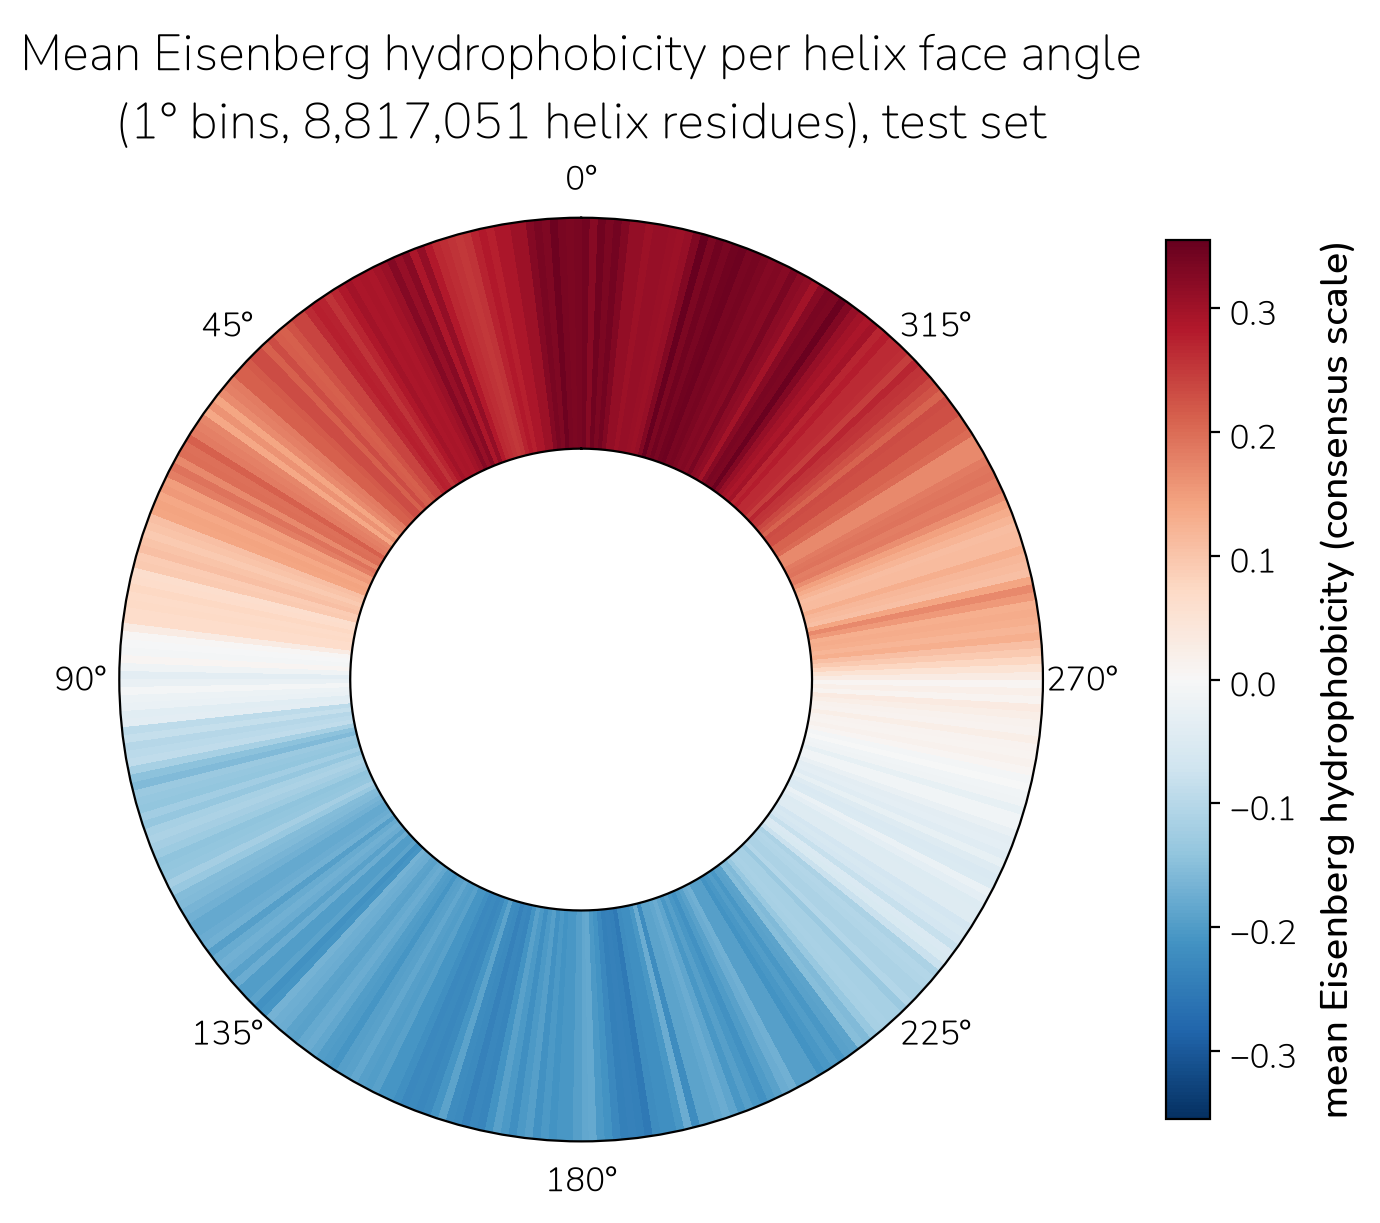

In [8]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

# Mean Eisenberg hydrophobicity of the residues per helix face angle, over all helix residues of the proteins in the results
ANGLE_WIDTH = 1  # degrees
by_angle = (
    helix_residues.with_columns(
        angle_bin=((pl.col("helix_face") + 180) // ANGLE_WIDTH).clip(0, 360 // ANGLE_WIDTH - 1).cast(pl.Int32),
        h=pl.col("aa").replace_strict(EISENBERG, return_dtype=pl.Float64),
    )
    .group_by("angle_bin")
    .agg(mean_h=pl.col("h").mean(), n=pl.len())
    .sort("angle_bin")
)
theta = np.deg2rad(by_angle["angle_bin"].to_numpy() * ANGLE_WIDTH - 180 + ANGLE_WIDTH / 2)
mean_h = by_angle["mean_h"].to_numpy()

# a ring of 5-degree sectors, coloured by the mean Eisenberg hydrophobicity (consensus scale) of the residues at that angle
limit = np.abs(mean_h).max()
norm = Normalize(-limit, limit)  # centred on 0: the sign separates hydrophobic and hydrophilic
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw={"projection": "polar"})
ax.bar(theta, 1, bottom=1, width=np.deg2rad(ANGLE_WIDTH), color=theme.HYDROPHOBICITY(norm(mean_h)), linewidth=0, antialiased=False)  # no borders between sectors
ax.set_rlim(0, 2)
ax.set_yticks([])
ax.grid(False)
ax.set_theta_zero_location("N")  # 0 degrees at the top
theme.inner_border(ax)
fig.colorbar(ScalarMappable(norm, theme.HYDROPHOBICITY), ax=ax, shrink=0.7, pad=0.1, label="mean Eisenberg hydrophobicity (consensus scale)")
ax.set_title(f"Mean Eisenberg hydrophobicity per helix face angle ({ANGLE_WIDTH}° bins, {by_angle['n'].sum():,} helix residues), test set")
plt.tight_layout()
plt.show()

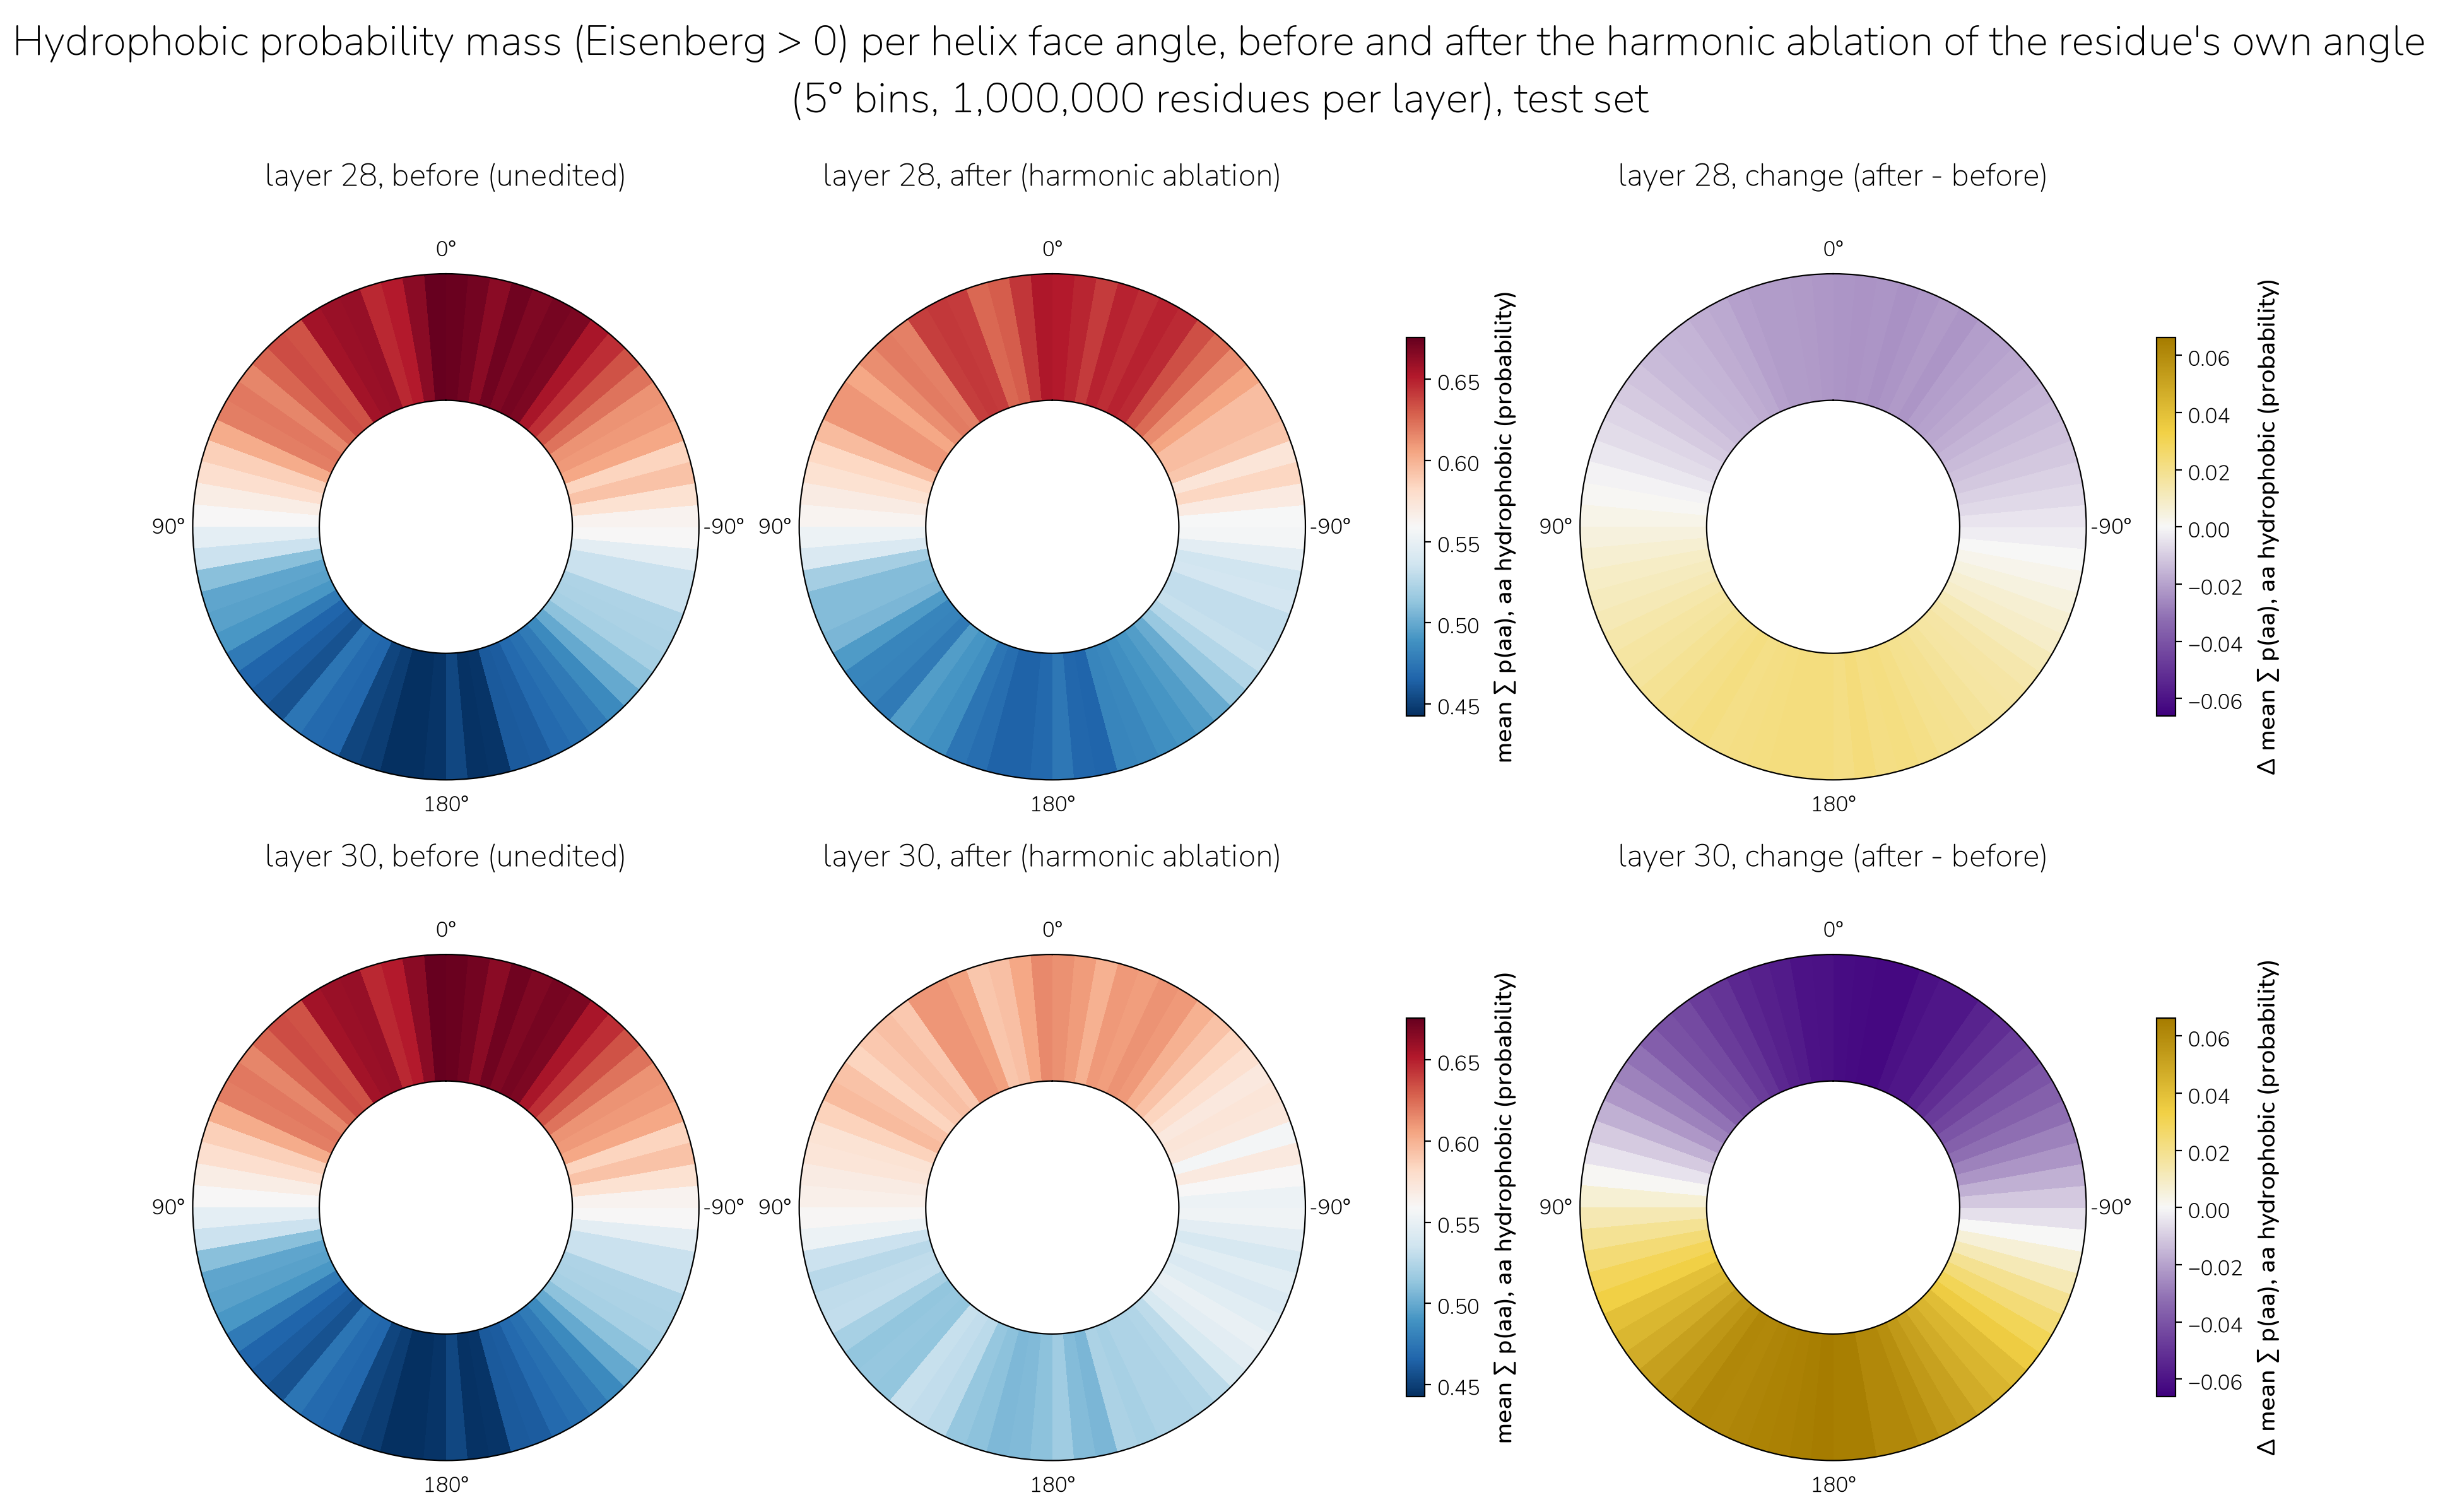

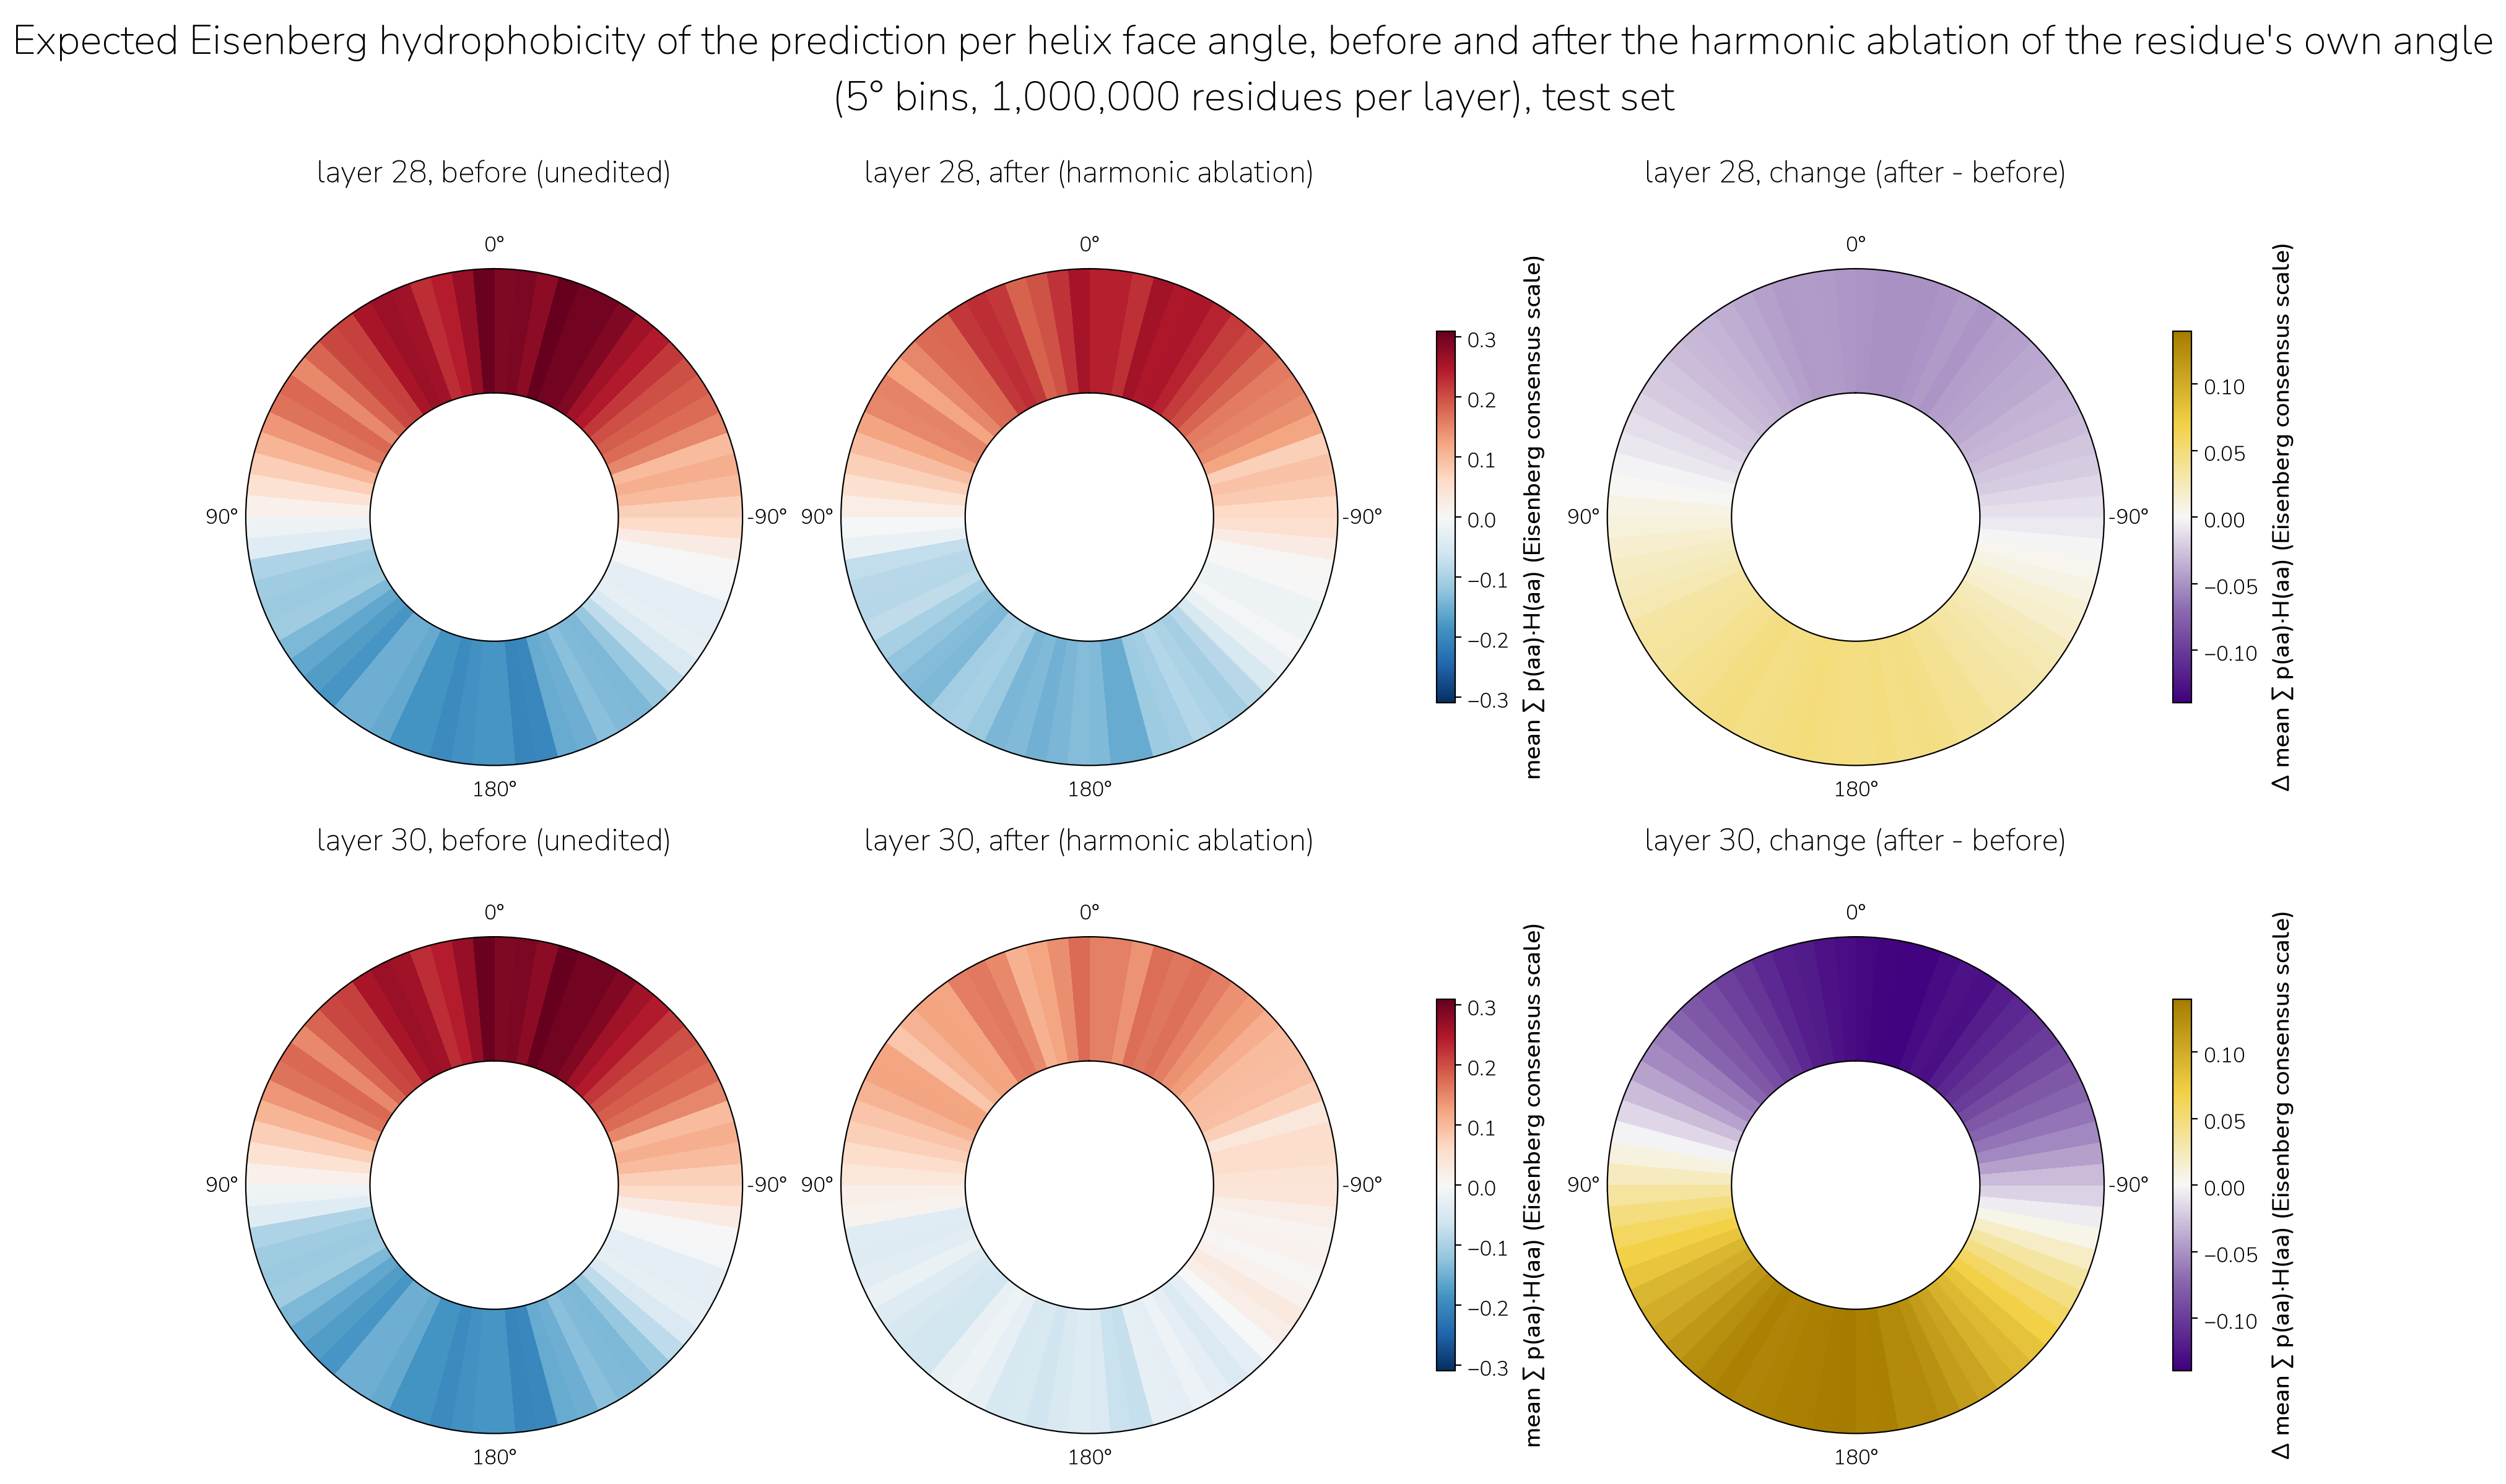

layer,angle_bin,hydrophobic_mass before,h_pred before,hydrophobic_mass after,h_pred after,hydrophobic_mass change,h_pred change,n
i32,i32,f32,f32,f32,f32,f32,f32,u32
28,0,0.453,-0.1821,0.4745,-0.1374,0.0215,0.0447,13913
28,35,0.6744,0.2893,0.6514,0.2399,-0.0231,-0.0494,13191
28,36,0.6757,0.3055,0.6534,0.2579,-0.0223,-0.0476,13838
28,71,0.4449,-0.1811,0.4674,-0.1346,0.0224,0.0466,13832
30,0,0.453,-0.1821,0.5176,-0.0473,0.0647,0.1348,13913
30,35,0.6744,0.2893,0.6121,0.1556,-0.0624,-0.1336,13191
30,36,0.6757,0.3055,0.6148,0.1758,-0.0609,-0.1297,13838
30,71,0.4449,-0.1811,0.5111,-0.0418,0.0662,0.1393,13832


In [9]:
# Hydrophobicity of the prediction per helix face angle, before and after the harmonic ablation of the residue's own angle
WHEEL_WIDTH = 5  # degrees
SCORES = {  # column: (title, colorbar label)
    "hydrophobic_mass": ("Hydrophobic probability mass (Eisenberg > 0)", "mean Σ p(aa), aa hydrophobic (probability)"),
    "h_pred": ("Expected Eisenberg hydrophobicity of the prediction", "mean Σ p(aa)·H(aa) (Eisenberg consensus scale)"),
}
steered = results.filter(pl.col("edit").is_in(["none", "harmonic"])).select("accession", "i", "layer", "edit", "helix_face", "aa_log_probs")
p = np.exp(steered["aa_log_probs"].cast(pl.Array(pl.Float32, len(AA))).to_numpy())  # (rows, 20), amino acids in the order of AA
scores = steered.drop("aa_log_probs").with_columns(
    hydrophobic_mass=p[:, in_hydrophobic].sum(1),  # raw sum over the 20 amino acids, not renormalised
    h_pred=p @ np.array([EISENBERG[a] for a in AA], dtype=np.float32),
    angle_bin=((pl.col("helix_face") + 180) // WHEEL_WIDTH).clip(0, 360 // WHEEL_WIDTH - 1).cast(pl.Int32),
)
del p

# per residue: the score before (edit "none") and after (edit "harmonic"), then the means per layer and 5-degree bin
wheels = (
    scores.filter(pl.col("edit") == "none")
    .join(scores.filter(pl.col("edit") == "harmonic").select("accession", "i", "layer", *[pl.col(s).alias(f"{s} after") for s in SCORES]),
          on=["accession", "i", "layer"])
    .group_by("layer", "angle_bin")
    .agg(n=pl.len(), *[pl.col(s).mean().alias(f"{s} before") for s in SCORES], *[pl.col(f"{s} after").mean() for s in SCORES],
         *[(pl.col(f"{s} after") - pl.col(s)).mean().alias(f"{s} change") for s in SCORES])
    .sort("layer", "angle_bin")
)


def wheel(ax, theta, values, norm, cmap, title):
    """A ring of sectors coloured by `values`, 0 degrees (toward the protein centroid) at the top."""
    ax.bar(theta, 1, bottom=1, width=np.deg2rad(WHEEL_WIDTH), color=cmap(norm(values)), linewidth=0, antialiased=False)  # no borders between sectors
    ax.set_rlim(0, 2)
    ax.set_yticks([])
    ax.grid(False)
    ax.set_theta_zero_location("N")  # 0 degrees at the top
    ax.set_thetagrids([0, 90, 180, 270], ["0°", "90°", "180°", "-90°"])
    theme.inner_border(ax)
    ax.set_title(title, pad=28)  # above the 0° label


for score, (name, label) in SCORES.items():
    both = wheels.select(f"{score} before", f"{score} after").to_numpy()
    if score == "h_pred":  # centred on 0: the sign separates hydrophobic and hydrophilic
        limit = np.abs(both).max()
        norm, cmap = Normalize(-limit, limit), theme.HYDROPHOBICITY
    else:
        norm, cmap = Normalize(both.min(), both.max()), theme.HYDROPHOBICITY
    limit = np.abs(wheels[f"{score} change"].to_numpy()).max()
    change_norm = Normalize(-limit, limit)  # symmetric, centred on 0
    fig, axes = plt.subplots(len(LAYERS), 3, figsize=(17, 6 * len(LAYERS)), subplot_kw={"projection": "polar"}, layout="constrained")
    fig.get_layout_engine().set(wspace=0.02, h_pad=0.15)  # wheels close together; some room between the rows and below the title
    for row, layer in zip(axes, LAYERS):
        w = wheels.filter(pl.col("layer") == layer)
        theta = np.deg2rad(w["angle_bin"].to_numpy() * WHEEL_WIDTH - 180 + WHEEL_WIDTH / 2)
        wheel(row[0], theta, w[f"{score} before"].to_numpy(), norm, cmap, f"layer {layer}, before (unedited)")
        wheel(row[1], theta, w[f"{score} after"].to_numpy(), norm, cmap, f"layer {layer}, after (harmonic ablation)")
        wheel(row[2], theta, w[f"{score} change"].to_numpy(), change_norm, theme.DELTA, f"layer {layer}, change (after - before)")
        fig.colorbar(ScalarMappable(norm, cmap), ax=row[:2], shrink=0.7, label=label)  # one scale for before and after
        fig.colorbar(ScalarMappable(change_norm, theme.DELTA), ax=row[2], shrink=0.7, label=f"Δ {label}")
    fig.suptitle(f"{name} per helix face angle, before and after the harmonic ablation of the residue's own angle\n"
                 f"({WHEEL_WIDTH}° bins, {w['n'].sum():,} residues per layer), test set", wrap=False)
    plt.show()

# the means at 0 and 180 degrees, and the range of the change
display(wheels.filter(pl.col("angle_bin").is_in([0, 35, 36, 71])).with_columns(pl.exclude("layer", "angle_bin", "n").round(4)))